# **Problema 1: Integración numérica de flujos**

Considere los siguientes campos de velocidad dependientes del tiempo $\mathbf{u}(\mathbf{x}, t)$ en el caso bidimensional $\mathbf{x} = x~\mathbf{\hat{x}}+ y~\mathbf{\hat{y}}$.
En cada caso, adimensionalice los campos y calcule numéricamente las trayectorias y la evolución de las líneas de corriente eligiendo puntos de colocación iniciales más apropiados para el flujo en cuestión:

(i) Una fuente lineal de caudal constante $Q$ superpuesta a una corriente uniforme cuya velocidad aumenta linealmente con el tiempo $U(t) = \gamma_0 t$.

(ii) Una fuente lineal de caudal constante $Q$ superpuesta a un torbellino cuya circulación $\Gamma$ decrece exponencialmente con un tiempo característico $\tau$.
_Ayuda: Tras adimensionalizar quedará un parámetro libre. Bárralo para estudiar los distintos regímenes._

(iii) Una fuente lineal de caudal constante $Q$ superpuesta a una corriente uniforme oscilante con velocidad $U(t) = U_0\cos(\omega t)$.


## Definiciones

### Runge-Kutta

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#Runge-Kutta a orden 1:
#Euler:
def esquema1(X, u, t, dt):
    k = u(X,t)
    return X + dt*k

#Runge-Kutta a orden 2:
#Heun:
def esquema2_H(X,u,t,dt):
    k1 = u(X,t)
    k2 = u(X+dt*k1,t+dt)
    return X + dt *(k1+k2)/2
#Punto medio:
def esquema2_pm(X,u,t,dt):
    k1 = u(X,t)
    k2 = u(X + dt*k1/2, t + dt/2)
    return X + dt*k2

#Runge-Kutta a orden 4:
#RK4:
def esquema4(X,u,t,dt):
    k1 = u(X,t)
    k2 = u(X + dt*k1/2, t + dt/2)
    k3 = u(X + dt*k2/2 ,t + dt/2)
    k4 = u(X + dt*k3, t + dt)
    return X + dt*(k1 + 2*k2 + 2*k3 + k4)/6

### Trayectorias

In [ ]:
esquema = esquema2_H #Selecciono el orden de RK que quiero usar

In [ ]:
def trayectoria(X0, u, N, dt):
    """
    Calcula numéricamente la solución a dX/ds = u(X,t) cómo
    un arreglo, usando el esquema definido previamente

    Parámetros:
      X0: Condición inicial cómo arreglo de dimensión d
      u : Campo de velocidades cómo función de (x,t)
      N : Número de pasos temporales
      dt: Paso temporal
    """
    d = X0.shape[0]            # Dimensión del problema
    ts = np.arange(0, N+1)*dt  # Tiempos donde calcularé la solución
    Xs = np.zeros((N+1, d))    # Solución aproximada
    Xs[0] = X0                 # Impongo la condición inicial a t=0
    for j in range(N):
        # Aplico esquema sobre Xs[j] para obtener Xs[j+1]
        Xs[j+1] = esquema(Xs[j], u, ts[j], dt)
    return ts, Xs

### Lineas de corriente

In [ ]:
esquema = esquema2_H #Selecciono el orden de RK que quiero usar

In [ ]:
def linea_de_corriente(l0, u, t, N, ds):
    """
    Calcula numéricamente la solución a dX/ds = u(X,t) cómo
    un arreglo, usando el esquema definido previamente

    Parámetros:
      l0: Origen de la línea cómo arreglo de dimensión d
      u : Campo de velocidades cómo función de (x,t)
      t : Tiempo para el cual se está calculando la línea
      N : Número de pasos en s
      ds: Paso del parametrizador
    """
    d = l0.shape[0]            # Dimensión del problema
    s = np.arange(0, N+1)*ds   # Valores del parametrizador s
    ls = np.zeros((N+1, d))    # Solución aproximada a lo largo de s
    ls[0] = l0                 # Impongo la condición inicial a s=0

    # Construyo una función que me genere la función u(x) a un tiempo
    # dado t y tome s cómo parámetro mudo (lo ignora)
    u_lc = lambda x, _: u(x, t)

    for j in range(N):
        # Aplico esquema sobre ls[j] para obtener ls[j+1]
        # El parámetro t es mudo (ver arriba u_lc)
        ls[j+1] = esquema(ls[j], u_lc, t, ds)
    return s, ls

## Caso 1

$\mathbf{U'}(\mathbf{r'},t') = B (\frac{A}{r'^2}\mathbf{r}+t \hat{\mathbf{x}}$)

con

$B = \frac{ \tau^2 \gamma_0 }{R}$

$A=\frac{Q}{2 \pi R \gamma_0 \tau}$

In [ ]:
esquema = esquema1 #Orden de RK

Lo que hacemos acá es variar el valor de A, el cual es el que nos dará una diferencia en la dinamica.

Con A muy chicos, el campo de velocidad que domina es el campo uniforme en x, despues de un tiempo chico.

Con A muy grandes, el campo de velocidad que domina es el de la fuente radial.

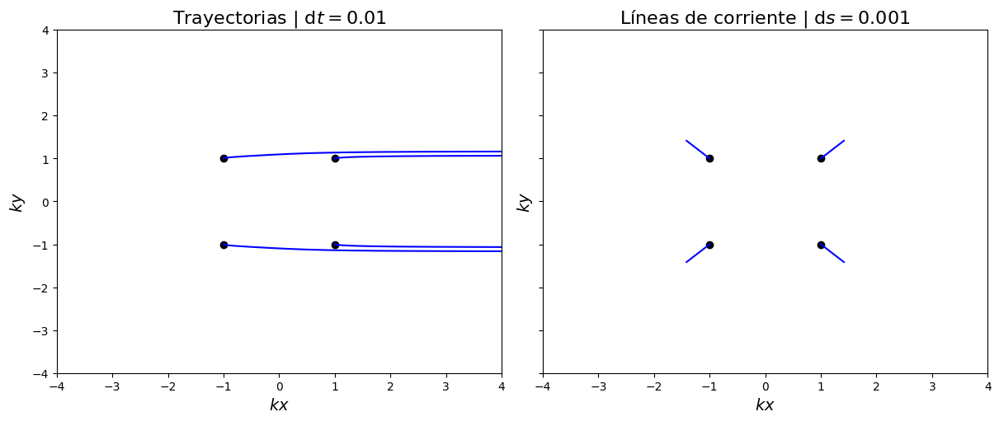

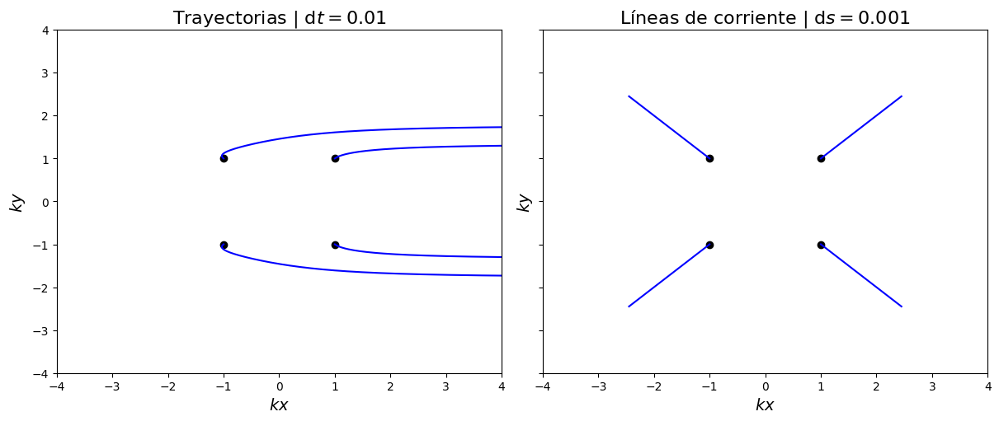

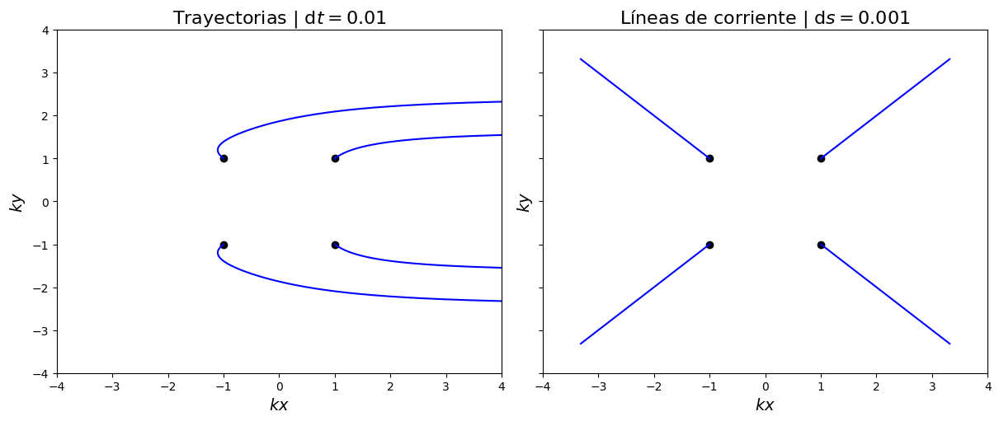

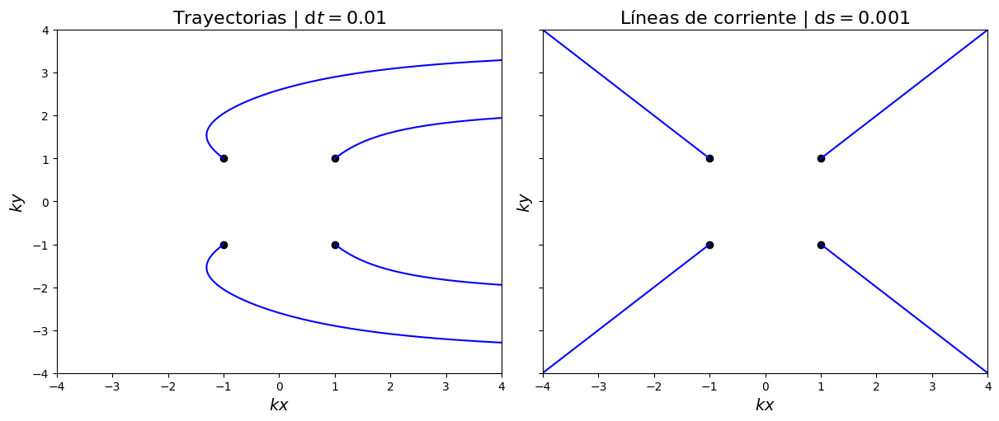

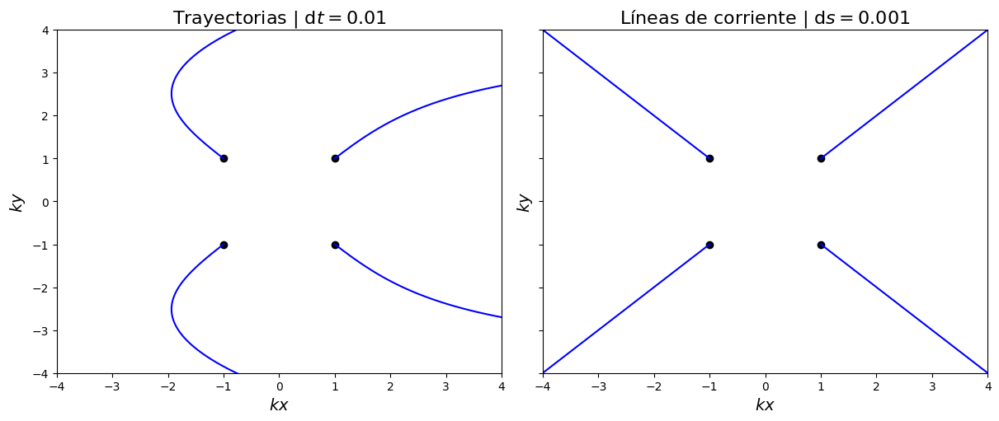

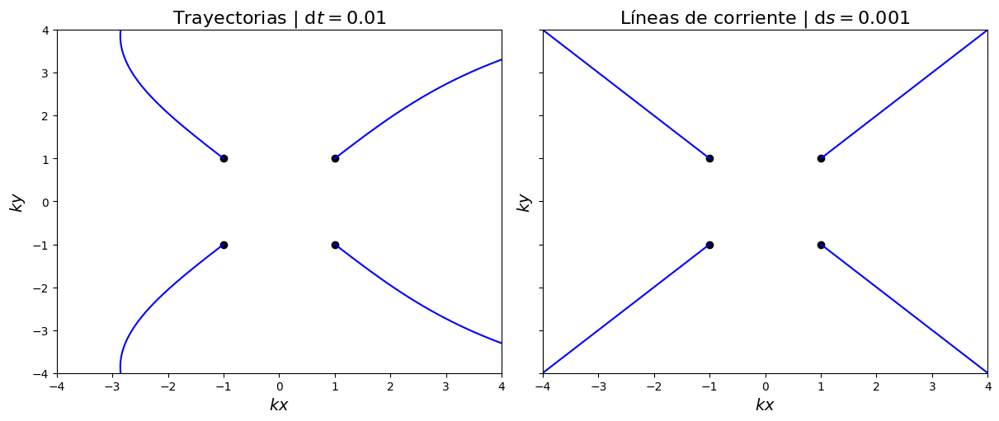

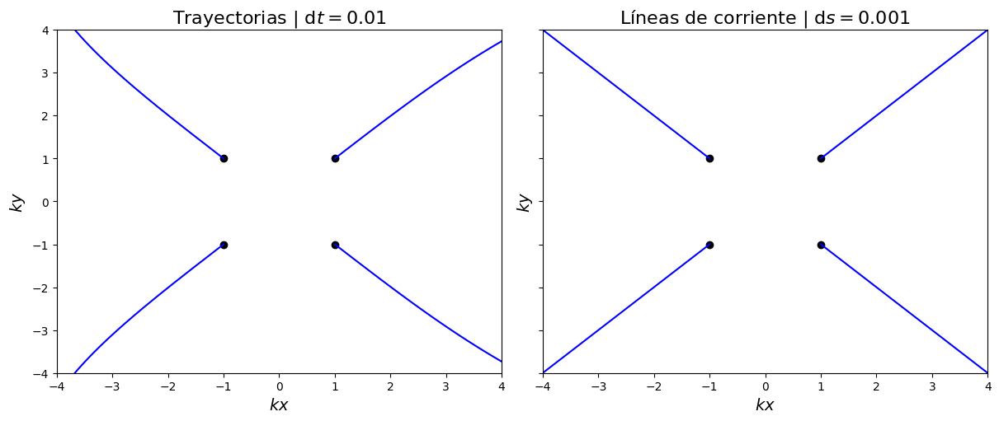

In [ ]:
def u(X,t):
  # A = 0.1
  B = 1
  r = np.linalg.norm(X)

  return B * (A * X / r**2 + t * np.array([1,0]))


N = 1000
dt = 1e-2
p0s = np.array([[-1, -1], [1, -1], [-1, 1], [1, 1]])

for A in [0.1,0.5,1,2,5,10,20]:
    fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(12,5), constrained_layout=True,
                                  sharex=True, sharey=True)
    for i in range(4):
      _, Xs = trayectoria(p0s[i], u, N, dt)
      ax1.plot(Xs[0,0], Xs[0,1], "ko")
      ax1.plot(Xs[:,0], Xs[:,1], "b-")

    N = 10000
    ds = 1e-3


    for i in range(4):
      _, ls = linea_de_corriente(p0s[i], u, 0, N, ds)
      ax2.plot(ls[0,0], ls[0,1], "ko")
      ax2.plot(ls[:,0], ls[:,1], "b-")

    ax1.set_xlim(-4,4)
    ax1.set_ylim(-4,4)
    ax1.set_xlabel('$kx$', fontsize=14)
    ax1.set_ylabel('$ky$', fontsize=14)
    ax1.set_title(f'Trayectorias | d$t={dt}$', fontsize=16)
    ax2.set_xlabel('$kx$', fontsize=14)
    ax2.set_ylabel('$ky$', fontsize=14)
    ax2.set_title(f'Líneas de corriente | d$s={ds}$', fontsize=16)

## Caso 2

$\mathbf{U'}(\mathbf{r'},t') = \frac{B}{t'}(A\mathbf{\hat{r}} + e^{-t'} \mathbf{\hat{\theta}} )$

con

$A=\frac{Q}{\Gamma}$

$B = \frac{\tau \Gamma}{2 \pi R^2}$

In [ ]:
esquema = esquema1 #Orden de RK

Lo que hacemos acá es variar el valor de A, el cual es el que nos dará una diferencia en la dinamica.

Con A muy chicos, el campo de velocidades que domina es el correspondiente al vortice.

Con A muy grandes, el campo de velocidades que domina es el correspondiente a la fuente radial.

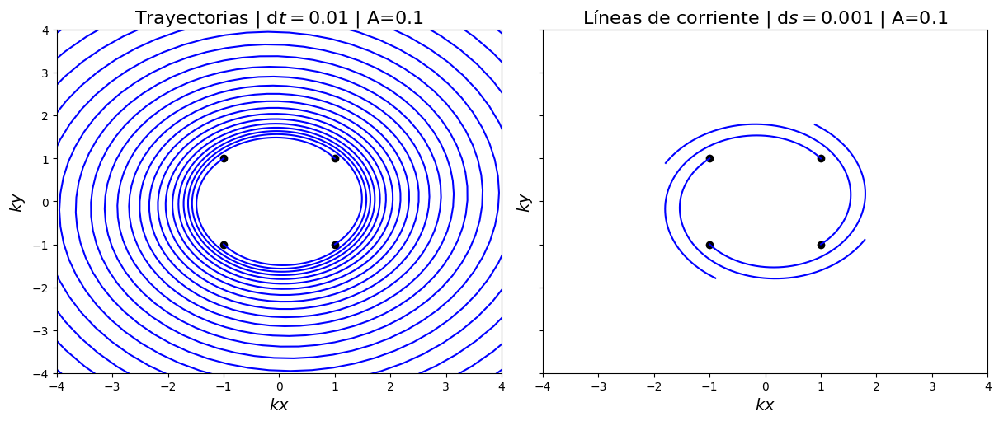

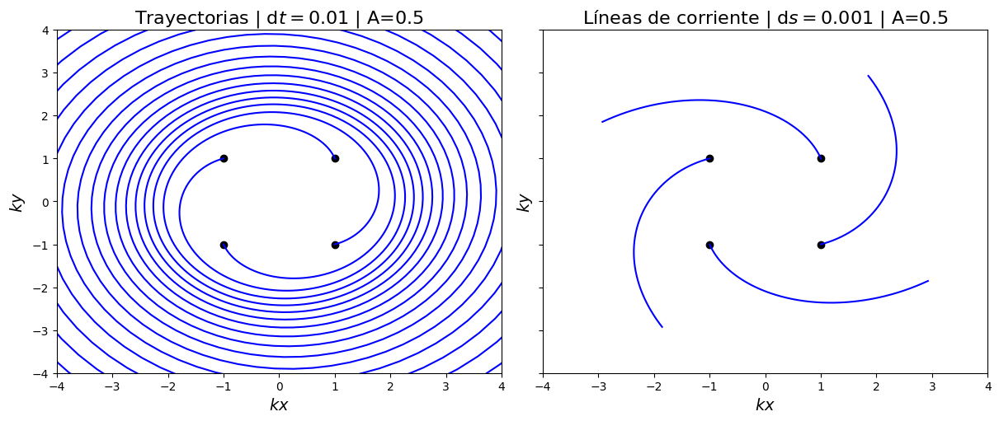

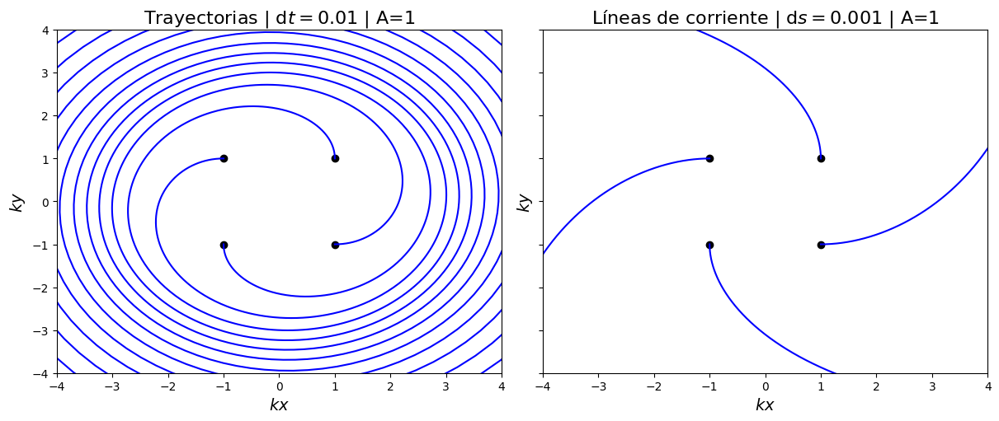

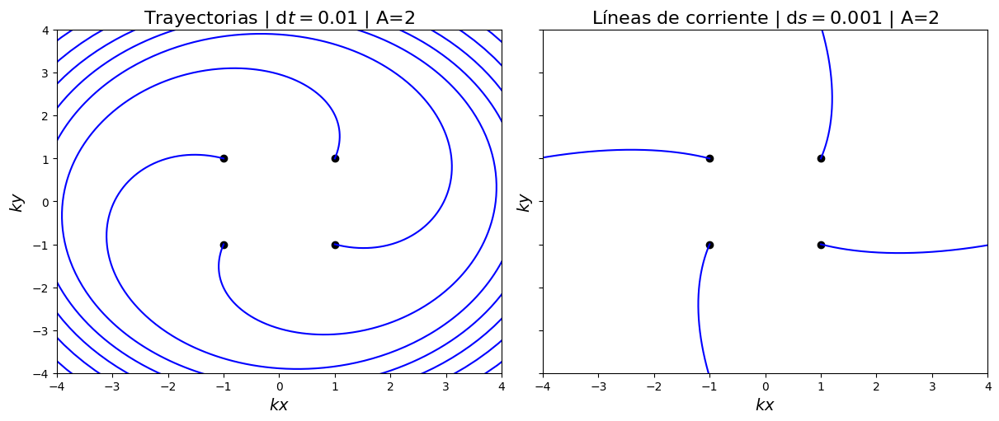

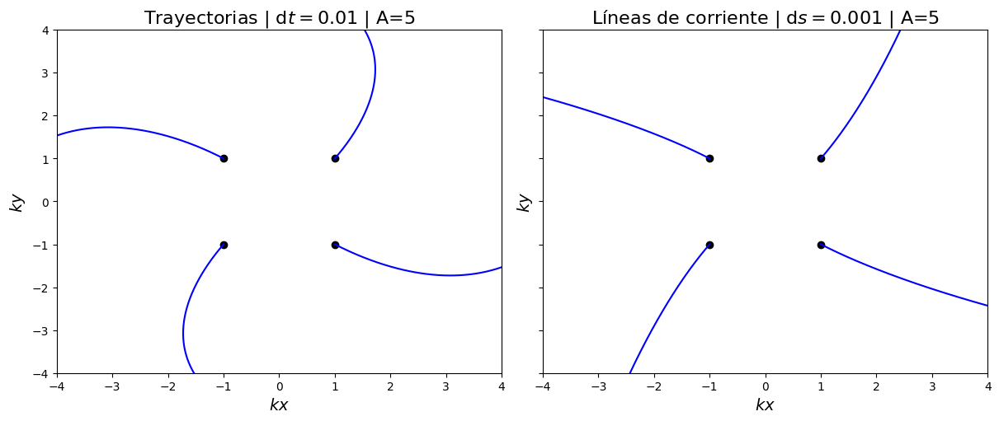

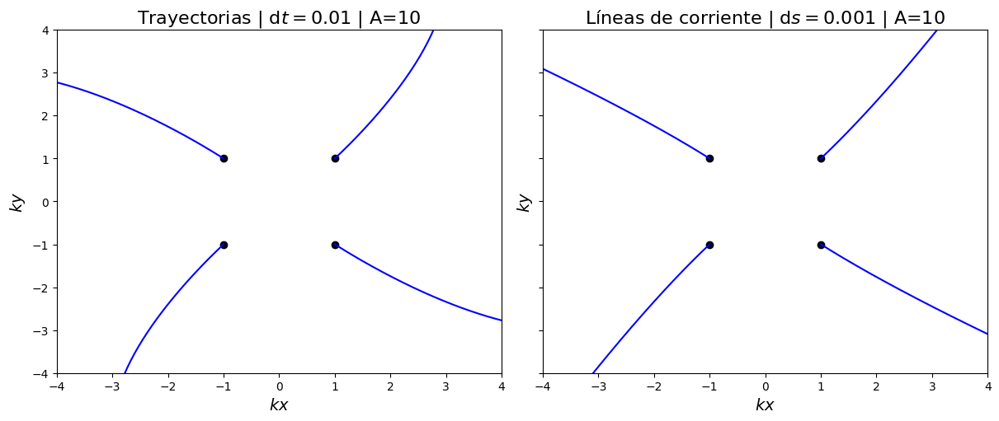

In [ ]:
#A = 1

def u(X,t):
  B = 1
  r = np.linalg.norm(X)
  r_vers = X/r
  theta_vers = np.array([-X[1], X[0]])/r

  return (B/r) * (A * r_vers + np.exp(t) * theta_vers)


N = 1000
dt = 1e-2
p0s = np.array([[-1, -1], [1, -1], [-1, 1], [1, 1]])


for A in [0.1,0.5,1,2,5,10]:

  fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(12,5), constrained_layout=True,
                               sharex=True, sharey=True)
  for i in range(4):
    _, Xs = trayectoria(p0s[i], u, N, dt)
    ax1.plot(Xs[0,0], Xs[0,1], "ko")
    ax1.plot(Xs[:,0], Xs[:,1], "b-")

  N = 10000
  ds = 1e-3
  for i in range(4):
    _, ls = linea_de_corriente(p0s[i], u, 0, N, ds)
    ax2.plot(ls[0,0], ls[0,1], "ko")
    ax2.plot(ls[:,0], ls[:,1], "b-")

  ax1.set_xlim(-4,4)
  ax1.set_ylim(-4,4)
  ax1.set_xlabel('$kx$', fontsize=14)
  ax1.set_ylabel('$ky$', fontsize=14)
  ax1.set_title(f'Trayectorias | d$t={dt}$ | A={A}', fontsize=16)
  ax2.set_xlabel('$kx$', fontsize=14)
  ax2.set_ylabel('$ky$', fontsize=14)
  ax2.set_title(f'Líneas de corriente | d$s={ds}$ | A={A}', fontsize=16)

## Caso 3

$\mathbf{U'}(\mathbf{r'},t') = \frac{A}{C}(\frac{B}{r'}\mathbf{\hat{r}} + \cos(C t') \mathbf{\hat{x}} )$

con

$ A = \frac{\tau U_0}{R} $

$ B = \frac{Q}{2\pi R U_0} $

$ C = \omega \tau \Rightarrow \tau = \frac{C}{\omega} \Rightarrow \frac{A}{C} = \frac{U_0}{\omega R}$

In [ ]:
esquema = esquema1 #Orden de RK

Lo que hacemos acá es variar el valor de B, el cual es el que nos dará una diferencia en la dinamica.

Con B muy chicos, el campo de velocidades que domina es el correspondiente al armonico en la dirección de x.

Con B muy grandes, el campo de velocidades que domina es el correspondiente a la fuente radial.

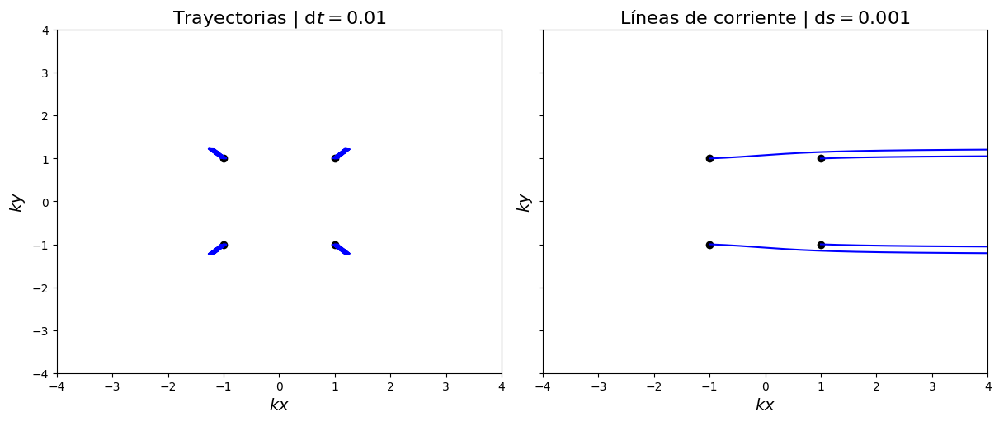

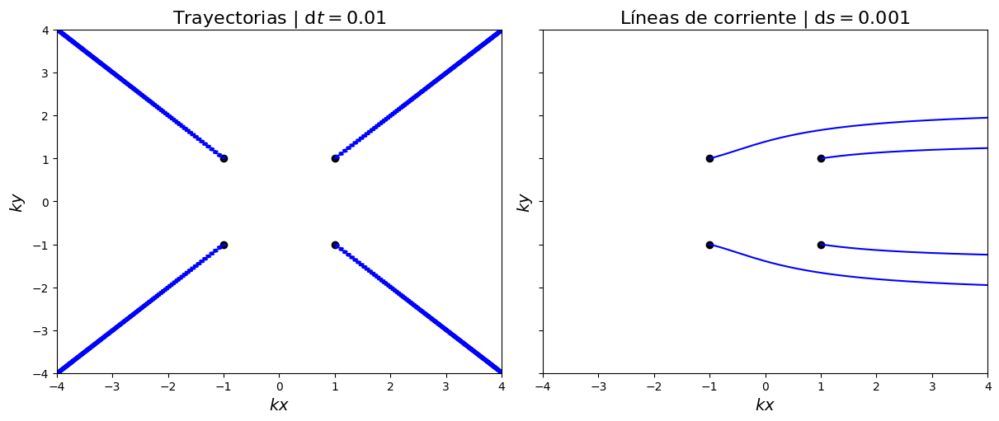

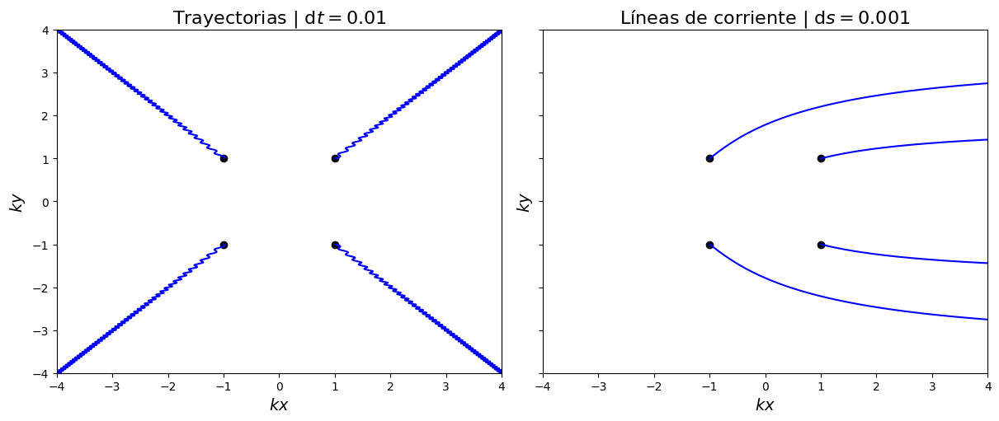

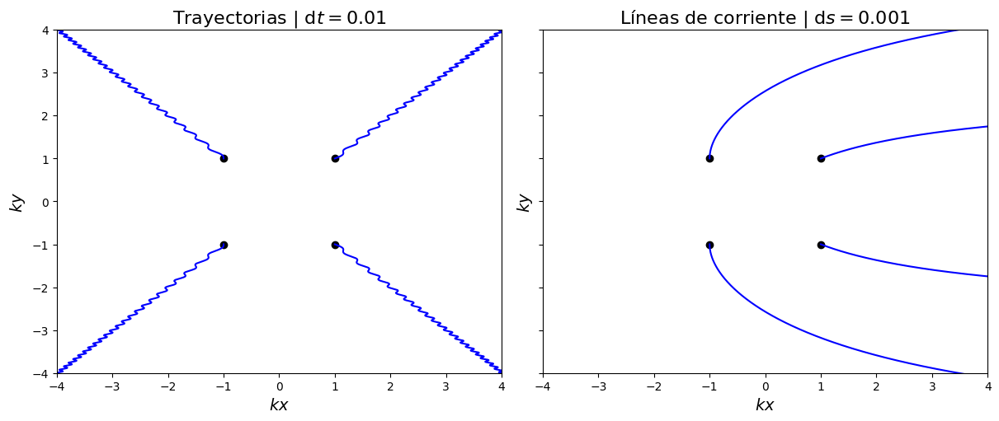

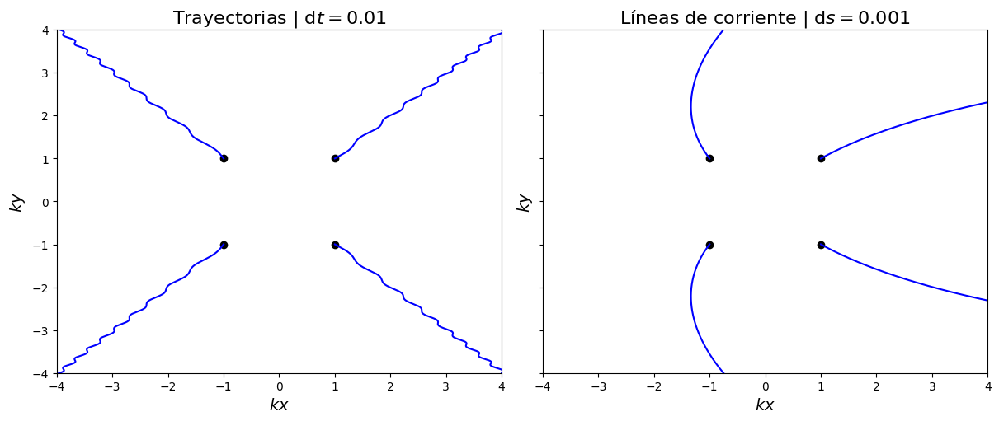

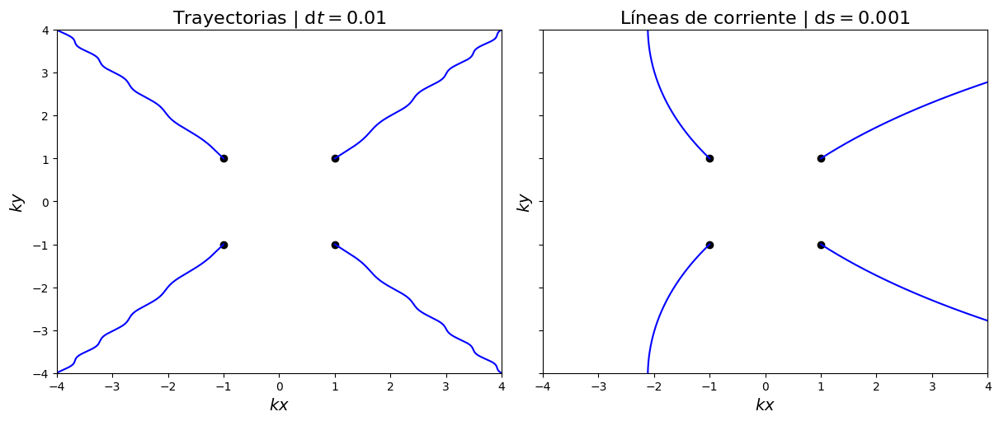

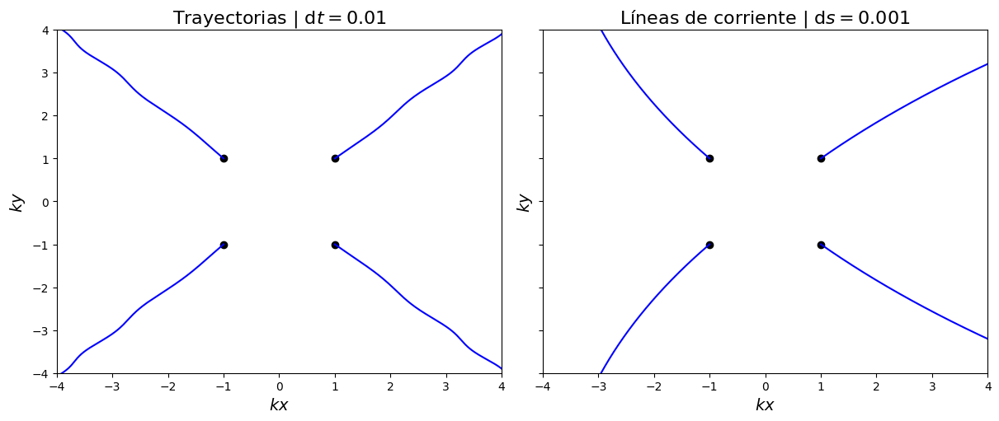

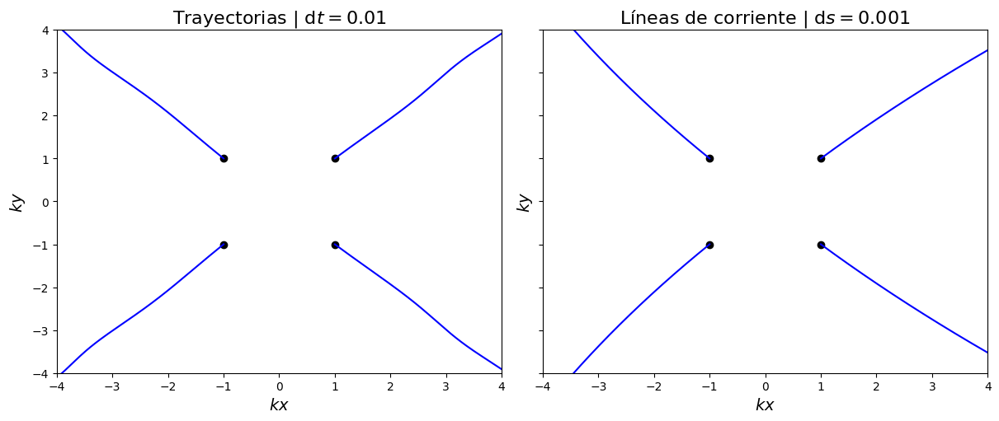

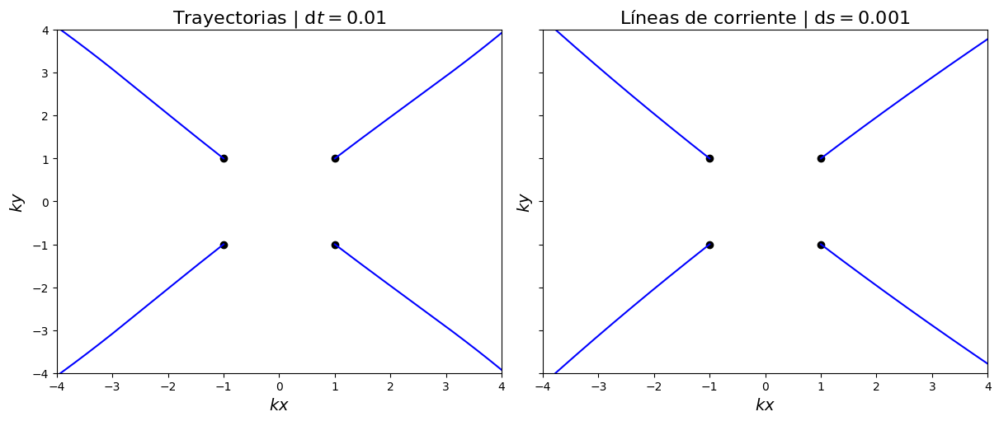

In [ ]:
A = 5
# B = 4
C = 10
def u(X,t):

  r = np.linalg.norm(X)
  r_vers = X/r

  return (A/C) * ( (B/r)*r_vers + np.cos(C * t) *np.array([1,0]) )


N = 1000
dt = 1e-2
p0s = np.array([[-1, -1], [1, -1], [-1, 1], [1, 1]])


for B in [0.1,0.5,1,2,5,10,20,40,100]:
    fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(12,5), constrained_layout=True,
                                  sharex=True, sharey=True)
    for i in range(4):
      _, Xs = trayectoria(p0s[i], u, N, dt)
      ax1.plot(Xs[0,0], Xs[0,1], "ko")
      ax1.plot(Xs[:,0], Xs[:,1], "b-")

    N = 10000
    ds = 1e-3
    for i in range(4):
      _, ls = linea_de_corriente(p0s[i], u, 0, N, ds)
      ax2.plot(ls[0,0], ls[0,1], "ko")
      ax2.plot(ls[:,0], ls[:,1], "b-")

    ax1.set_xlim(-4,4)
    ax1.set_ylim(-4,4)
    ax1.set_xlabel('$kx$', fontsize=14)
    ax1.set_ylabel('$ky$', fontsize=14)
    ax1.set_title(f'Trayectorias | d$t={dt}$', fontsize=16)
    ax2.set_xlabel('$kx$', fontsize=14)
    ax2.set_ylabel('$ky$', fontsize=14)
    ax2.set_title(f'Líneas de corriente | d$s={ds}$', fontsize=16)

# **Problema 2: Integración mediante PINNs.**
Elija un flujo del Problema 1 o del Problema 2. Compararemos las trayectorias obtenidas (sea analítica o numéricamente) con lo obtenido mediante el uso de Redes Neuronales Informadas por la Física (PINNs, vease apunte).
Limitese a una única trayectoria, dada por un único punto inicial $(x_0, y_0)$ y un dado conjunto de parámetros adimensionales (si elige un flujo del Problema 1, antes adimensionalícelo).
Elija un tiempo de integración $T$ tal que la dinámica es rica (puede ser el mismo que usó para integrar numéricamente).
En la celda a continuación le proporcionamos la estructura general de la PINN.

(i) Provea a la red con $10$ puntos de entrenamiento de datos, $20$ puntos de entrenamiento de física y $\lambda = 10^{-4}$, ambos equiespaciados en $[0, T]$ (asegúrese de incluir tanto $0$ cómo $T$), y entrénela durante $20000$ épocas. Grafique tanto el error de los datos cómo el de la física en función de la época para determinar. Interprete. ¿Cuantas épocas considera suficientes?

(ii) Utilice la red entrenada (con $20000$ épocas) para calcular la trayectoria más allá de $T$ y calcule el error $\epsilon(t) = |\mathbf{X}_\mathrm{PINN}(t) - \mathbf{X}(t)|$. Grafiquelo e interprete. ¿Hasta que valor de $t$ considera adecuada la red? ¿Puede identificar los tiempos donde $\mathbf{X}(t)$ corresponde a un punto de entrenamiento y/o de física? Repita esto para un entrenamiento con puntos de entrenamiento de física uniformemente distribuidos en $[0, 2T]$, **sin cambiar la cantidad**. ¿Mejora la aproximación? Interprete.

(iii) Manteniendo los $20$ puntos de entrenamiento de física, varíe la cantidad de puntos de entrenamiento de datos $N_d$ entre $2$ y $20$ y grafique el error medio $\epsilon_M = \sum_n \epsilon(t_n)$ para cada $N_d$. Interprete la ganancia de precisión teniendo en cuenta el tiempo de entrenamiento necesario. ¿Cambia la cantidad de épocas óptima para cada $N_d$?

(iv) Repita el inciso anterior pero manteniendo $N_d = 10$ puntos de entrenamiento de datos y varíe la cantidad de puntos de entrenamiento de física $N_f$ entre $5$ y $50$.

(v) Fijando $N_d=10$ y $N_f=20$, varie $\lambda$ logarítmicamente entre $10^{-6}$ y $10^{-1}$ y compare ambas funciones de pérdida y $\epsilon_M$ para cada caso.

(vi) (Opcional) Fijando $N_d$, $N_f$ y $\lambda$ a gusto, pruebe distintas arquitecturas para la red y compare sus desempeños. ¿Considera alguna óptima? _Ayuda: Por cuestiones de desempeño, evite redes con más de 3 capas ocultas._

## Item (i)


$\mathbf{U'}(\mathbf{r'},t') = B (\frac{A}{r'^2}\mathbf{r}+t \hat{\mathbf{x}}$)

con

$B = \frac{ \tau^2 \gamma_0 }{R}$

$A=\frac{Q}{2 \pi R \gamma_0 \tau}$

### Definiciones

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.autograd import Variable
import copy

from tqdm import trange



# La verdad parece mas rapido en cpu
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
torch.set_default_device(device)
torch.set_default_dtype(torch.float64)


class MLP(torch.nn.Module):

    def __init__(self,sizes):
        super().__init__()
        self.layers = torch.nn.ModuleList()
        for i in range(len(sizes)-1):
            self.layers.append(torch.nn.Linear(sizes[i],sizes[i+1]))

    def forward(self,x):
        h = x
        for hidden in self.layers[:-1]:
            h = torch.tanh(hidden(h))
        output = self.layers[-1]
        y = output(h)
        return y

### Runge-Kutta

Debemos generar datos de entrenamiento para la red neuronal. Para ello resolvemos la ecuación con Runge-Kutta. Para que sea preciso, usamos un esquema de orden 4.

In [ ]:
def esquema4(X,u,t,dt):
    k1 = u(X,t)
    k2 = u(X + dt*k1/2, t + dt/2)
    k3 = u(X + dt*k2/2 ,t + dt/2)
    k4 = u(X + dt*k3, t + dt)
    return X + dt*(k1 + 2*k2 + 2*k3 + k4)/6

Definimos el flujo y la integracion. Vamos a estar usando el campo adimensional

$ u'(r',t') = \hat r / r' + \hat x t' = \vec r / r'^2 + \hat x t' $

Definimos $ T = 3s $, aunque vamos a realizar la integracion durante un periodo mas largo para ya tener los datos para el resto de los incisos.


In [ ]:
def u(x, t):
    r = np.linalg.norm(x)

    u1 = x / r**2
    u2 = t * np.array([1, 0])
    return u1 + u2

T = 3
dt = 5e-4

# Vamos a integrar durante el doble de tiempo para tener mas datos
# pero vamos a ir regulando con cuales entrenamos
n_puntos = 2*int(T/dt)

# Creamos un array con #n_puntos numeros
t_sol = np.zeros(n_puntos)

# Creamos un array de #n_puntos puntos (arrays de largo 2)
x_sol = np.zeros((n_puntos,2))


# Condiciones iniciales
t_sol[0] = 0.0
x_sol[0] = np.array([-1,1])

Integramos

In [ ]:
# Uno menos xq ya estan los estados iniciales
for i in range(n_puntos-1):
    t_sol[i+1] = t_sol[i] + dt
    x_sol[i+1] = esquema4(x_sol[i], u, t_sol[i], dt)

Ahora extraemos 10 pares (tiempo, posicion) para entrenar con datos y 20 pares (tiempo, velocidad) para entrenar con la fisica. Todos los datos los sacamos del periodo $ t < T $

In [ ]:
N_datos = 10
N_fisica = 20

# Usamos los datos solo de la primera mitad de la trayectoria
paso_datos = int(1/2 * (n_puntos-1)/(N_datos-1))
paso_fisica = int(1/2 * (n_puntos-1)/(N_fisica-1))

x_train = x_sol[0:int(n_puntos/2):paso_datos]
t_train = t_sol[0:int(n_puntos/2):paso_datos]
t_fisica = t_sol[0:int(n_puntos/2):paso_fisica]



# Las pasamos a tensores de torch
X_train = torch.tensor(x_train)
# Los tiempos tienen que ser 2d con forma Nx1, en vez de 1d con forma N
T_train = torch.tensor(t_train).view(N_datos,1)
T_fisica = torch.tensor(t_fisica).view(N_fisica,1)



# Definimos el campo de forma que se pueda evaluar en
# tensores de tiempo y posicion y devuelva un tensor
def U_entrenamiento(X,T):
  # X es un tensor de N_fisica x 2
  # T es un tensor de N_fisica x 1 (dos indices!)
  R2 = torch.einsum("i j, i j -> i", X, X) # R^2_i = X_i j X_i j (sumado solo sobre j)
  U1 = torch.einsum("i j, i -> i j", X, 1/R2) # U1_i j = X_i j (1/R^2)_i (sin sumar nada)

  x_versor = torch.tensor([1,0])
  U2 = torch.einsum("i j, k -> i k", T, x_versor) # U2_i k = T_i j x_versor_k (sumando sobre j)
  return U1 + U2

Ahora definamos y entrenemos la red neuronal

In [ ]:
#Definimos la red
pinn = MLP([1, 32, 32,  2])

#Implementamos un optimizador
optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-4)

In [ ]:
epochs = 20000
l = 1e-4   # Lambda

# Vamos a guardar los errores para graficarlos
historial_error = np.zeros(epochs)
historial_mse_datos = np.zeros(epochs)
historial_mse_fisica = np.zeros(epochs)

# Vamos a querer derivar respecto al tensor de tiempos de
# fisica para sacar la velocidad
T_fisica.requires_grad = True

for epoch in trange(epochs):
    optimizer.zero_grad() #Borra gradientes de la iteracion anterior

    # Error en las posiciones de entrenamiento
    X_pinn_datos = pinn(T_train)
    MSE_datos = torch.mean((X_pinn_datos - X_train)**2)

    # Error en las velocdiades de entrenamiento
    X_pinn_fisica = pinn(T_fisica)
    dX_dT   = torch.autograd.grad(X_pinn_fisica[:, 0], T_fisica, torch.ones_like(X_pinn_fisica[:, 0]), create_graph=True)[0]
    dY_dT   = torch.autograd.grad(X_pinn_fisica[:, 1], T_fisica, torch.ones_like(X_pinn_fisica[:, 1]), create_graph=True)[0]
    U_pinn = torch.concatenate([dX_dT, dY_dT], axis=-1)
    MSE_fisica = torch.mean((U_pinn - U_entrenamiento(X_pinn_fisica, T_fisica))**2)

    # Ajustamos los pesos de la  red
    loss = MSE_datos + l * MSE_fisica
    loss.backward() #Calcula nuevos gradientes con backpropagation
    optimizer.step() #Actualiza los parámetros en base a sus gradientes

    # Guardamos los errores
    historial_error[epoch] = loss.item()
    historial_mse_datos[epoch] = MSE_datos.item()
    historial_mse_fisica[epoch] = MSE_fisica.item()

100%|██████████| 20000/20000 [00:51<00:00, 390.00it/s]


Graficamos la evolucion de los errores a lo largo del entrenamiento

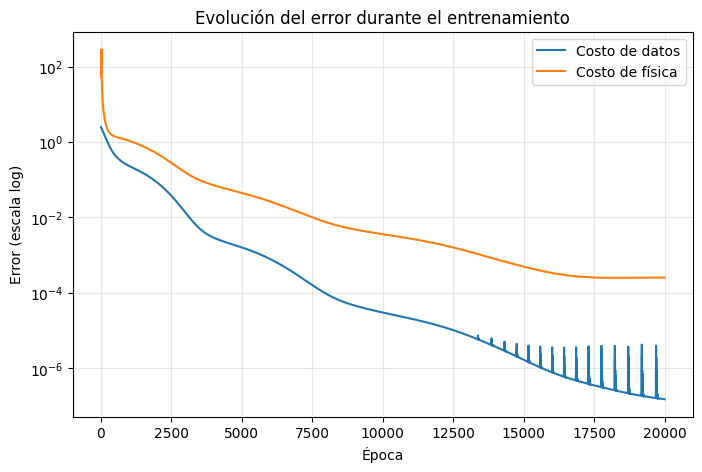

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(historial_mse_datos, label='Costo de datos')
plt.plot(historial_mse_fisica, label='Costo de física')
plt.yscale('log')
plt.xlabel('Época')
plt.ylabel('Error (escala log)')
plt.title('Evolución del error durante el entrenamiento')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

Ambos bajaron, por lo que el entrenamiento funciono. El error de fisica podria haber seguido bajando, pero el error de datos empezo a empeorar periodicamente, lo que indica que puede estar sobreajustando en vez de aprender. Entonces 20000 epochs es un buen punto para detener el entrenamiento

Visualizamos la trayectoria predicha por la PINN para $t<T$

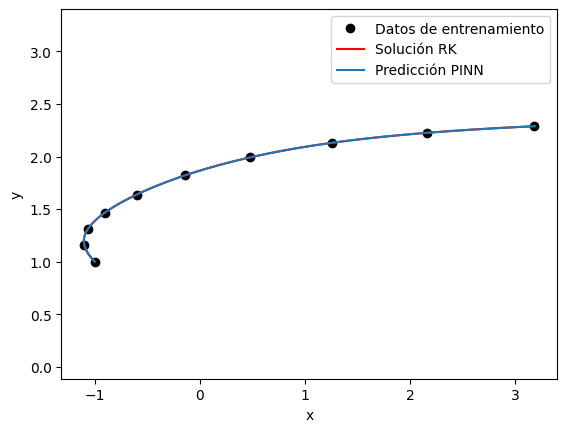

In [ ]:
# Prediccion de la red hasta 2T
T_pred = torch.tensor(t_sol).view(n_puntos,1)
X_pred = pinn(T_pred)
x_pred = X_pred.detach().cpu().numpy()

# Grafico
plt.plot(x_train[:,0], x_train[:, 1], "ko", label='Datos de entrenamiento')

# Tomamos solo la primera mitad de los puntos
plt.plot(x_sol[:int(n_puntos/2),0], x_sol[:int(n_puntos/2), 1], "r-", label='Solución RK')
plt.plot(x_pred[:int(n_puntos/2),0], x_pred[:int(n_puntos/2), 1], label='Predicción PINN')

plt.xlabel('x')
plt.ylabel('y')
plt.axis('equal')
plt.legend()
plt.show()

Parece perfecta

## Item (ii)

Volvemos a visualizar la trayectoria, pero esta vez hasta $ t = 2 T = 6s $

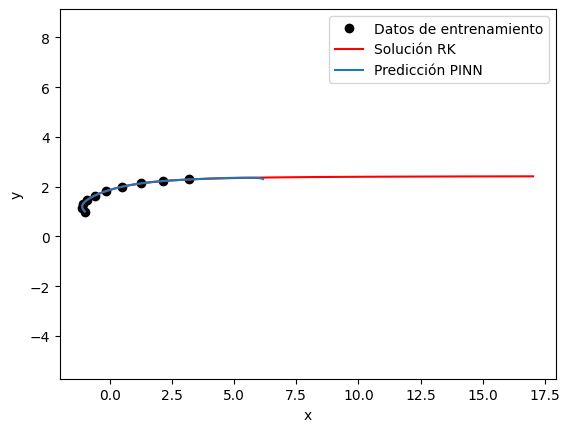

In [ ]:
# Graficamos los arrays enteros
plt.plot(x_train[:,0], x_train[:, 1], "ko", label='Datos de entrenamiento')
plt.plot(x_sol[:,0], x_sol[:, 1], "r-", label='Solución RK')
plt.plot(x_pred[:,0], x_pred[:, 1], label='Predicción PINN')

plt.xlabel('x')
plt.ylabel('y')
plt.axis('equal')
plt.legend()
plt.show()

Pareceria que la PINN se queda muy por detras. Para ver exactamente como depende del tiempo, vemos cada coordenada por separado a lo largo del tiempo.

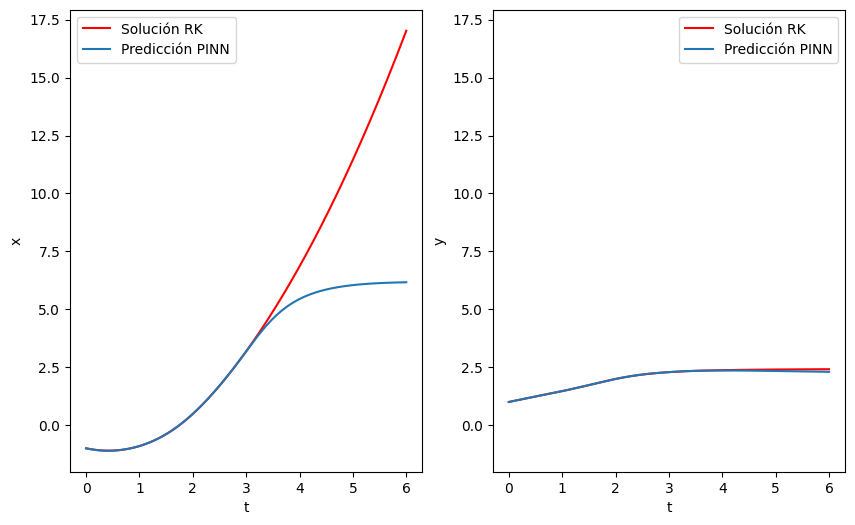

In [ ]:
plt.figure(figsize=(10, 6))

plt.subplot(1,2,1)

plt.plot(t_sol, x_sol[:, 0], "r-", label='Solución RK')
plt.plot(t_sol, x_pred[:, 0], label='Predicción PINN')

plt.xlabel('t')
plt.ylabel('x')
plt.legend()

lims = plt.ylim()

plt.subplot(1,2,2)

plt.plot(t_sol, x_sol[:, 1], "r-", label='Solución RK')
plt.plot(t_sol, x_pred[:, 1], label='Predicción PINN')

plt.xlabel('t')
plt.ylabel('y')
plt.legend()

plt.ylim(lims)

plt.show()

Se ve que aunque la prediccion es muy precisa hasta $ t = 3 $, despues empieza a errarle. Esto es mucho peor para la coordenada $x$, seguramente porque la red no aprendio correctamente como cambia el flujo variable en el tiempo: como la entrenamos para $t$ chico, piensa que su velocidad es siempre chica.

Visualizemos el error cuadratico a lo largo del tiempo

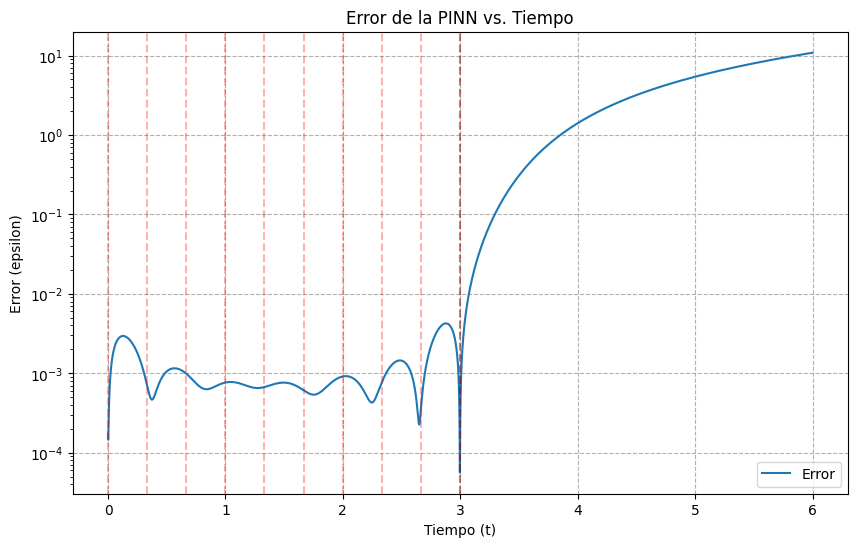

In [ ]:
diferencias = x_pred - x_sol

distancias = np.linalg.norm(diferencias, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(t_sol, distancias, label='Error')

plt.xlabel('Tiempo (t)')
plt.ylabel('Error (epsilon)')
plt.title('Error de la PINN vs. Tiempo')
plt.grid(True, linestyle='--')

plt.axvline(x=T, color="black", linestyle="--", alpha=0.3)

for t in t_train:
  plt.axvline(x=t, color="red", linestyle="--", alpha=0.3)

plt.yscale("log")
plt.legend()
plt.show()

Se ve claramente que el error se dispara apenas termina el intervalo de donde sacamos los datos de entrenamiento. Aunque hay varios valles en el error, no pareceria que se relacionan directamente con los tiempos de entrenamiento: lo que hace la optimizacion es hacer que en esos momentos la variacion cuando se cambian los parametros sea chica, no necesariamente la variacion cuando cambia el tiempo.

Se ve claramente que el error se dispara apenas termina el intervalo de donde sacamos los datos de entrenamiento. Los valles del error no siempre coinciden con los momentos en los que tomamos datos para el entrenamiento: por ejemplo un dato de entrenamiento en $t=1$ coincide con un pico del error, lo que parece una contradiccion con el proceso de entrenamiento. Lo que ocurre es que el costo que realmente minimiza la red en su entrenamiento no es cada error individual en los tiempos de entrenamiento, sino su promedio.

Si vemos el promedio del costo en $N_{datos}$ tiempos equiespaciados,

$ E_{promedio}(t) = \frac{1}{N_{datos}} \sum_{n \in \Bbb{Z}}  E(t+n \frac{T}{N_{datos}-1})   $

el grafico queda como la siguiente figura.

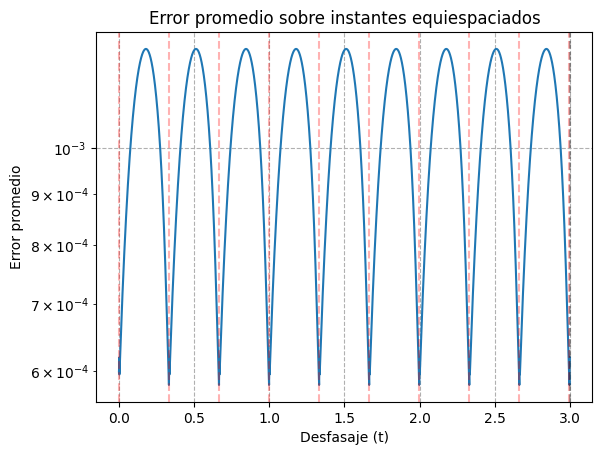

In [ ]:
promedios = np.zeros(int(n_puntos/2))

for i in range(int(n_puntos/2)):
  # El primer n es el que hace que i + n * paso sea 0 (o el minimo valor posible)
  n = - int(i / paso_datos)
  while i + n * paso_datos < n_puntos/2:
    promedios[i] += distancias[i + n * paso_datos]/N_datos
    n += 1


plt.plot(t_sol[:int(n_puntos/2)],promedios)
for t in t_train:
  plt.axvline(x=t, color="red", linestyle="--", alpha=0.3)

plt.xlabel('Desfasaje (t)')
plt.ylabel('Error promedio')
plt.title('Error promedio sobre instantes equiespaciados')
plt.grid(True, linestyle='--')

plt.axvline(x=T, color="black", linestyle="--", alpha=0.3)

plt.yscale("log")
plt.show()

El grafico permite identificar cual conjunto de $N_{datos}$ puntos equiespaciados son los que fueron usados en el entrenamiento: son aquellos para los cuales el error promedio se minimiza. En la figura se observa como al desfasar la grilla de 10 puntos equiespaciados respecto de los correspondientes a los tiempos de entrenamiento (desfasaje = 0) el error promedio sobre estos puntos crece hasta alcanzar un maximo cuando estos se encuentran a mitad de camino entre cada par de puntos de entrenamiento.

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib import rc
from IPython.display import HTML

rc('animation', html='jshtml')

movimiento = diferencias[:int(len(diferencias)/2)]

frames_por_segundo = 20
# en milisegundos
duracion = 30 * 1000

n_frames = int(duracion * frames_por_segundo / 1000)
intervalo = int(1000/frames_por_segundo) #tiempo entre frames


tiempo_fisico_por_frame = len(movimiento) * dt / n_frames

frames = diferencias[::int(len(movimiento)/n_frames)]
frames_entrenamiento = t_train / tiempo_fisico_por_frame

# Para que sea una lista de enteros
frames_entrenamiento=[int(n) for n in frames_entrenamiento]



fig, ax = plt.subplots()

ax.set_xlim([-0.005, 0.005])
ax.set_ylim([-0.005, 0.005])

punto = ax.scatter(diferencias[0][0], diferencias[0][1], color='green', marker='o', s=50, label="Prediccion PINN")
origen = ax.scatter(0, 0, color="black", marker= "o", s=50, label="Solucion RK")
ax.grid(color='gray', linestyle='--', linewidth=0.5)

ax.set_title('Posicion relativa de la particula real y la simulada por PINN')

plt.legend()
fig.show()

entrenamiento = False

def update(frame):
    punto.set_offsets(frames[frame])


    if (frame in frames_entrenamiento):
      entrenamiento=True
      origen.set_color("red")
    else:
      entrenamiento=False
      origen.set_color("black")


    return (punto,origen)

ani = animation.FuncAnimation(fig, update, frames=n_frames, interval=intervalo, blit=True, cache_frame_data=False)

plt.close()
HTML(ani.to_jshtml())

Entrenamos nuevamente, pero con los puntos de fisica distribuidos en $[0, 2T]$. Para eso tenemos que recrear los puntos de entrenamiento d efisica

In [ ]:
paso_fisica = int((n_puntos-1)/(N_fisica-1))

t_fisica = t_sol[0:n_puntos:paso_fisica]
T_fisica = torch.tensor(t_fisica).view(N_fisica,1)

In [ ]:
#Definimos la red
pinn_2 = MLP([1, 32, 32,  2])

#Implementamos un optimizador
optimizer = torch.optim.Adam(pinn_2.parameters(), lr=1e-4)


epochs = 20000 #Epochs
l = 1e-4   # Lambda

historial_error = np.zeros(epochs)
historial_mse_datos = np.zeros(epochs)
historial_mse_fisica = np.zeros(epochs)

T_fisica.requires_grad = True

for epoch in trange(epochs):
    optimizer.zero_grad() #Borra gradientes de la iteracion anterior

    # El error en las posiciones de entrenamiento
    X_pinn_datos = pinn_2(T_train)
    MSE_datos = torch.mean((X_pinn_datos - X_train)**2)

    # El error en las velocdiades de entrenamiento
    X_pinn_fisica = pinn_2(T_fisica)
    dX_dT   = torch.autograd.grad(X_pinn_fisica[:, 0], T_fisica, torch.ones_like(X_pinn_fisica[:, 0]), create_graph=True)[0] # Computamos dx/dt
    dY_dT   = torch.autograd.grad(X_pinn_fisica[:, 1], T_fisica, torch.ones_like(X_pinn_fisica[:, 1]), create_graph=True)[0] # Computamos dy/dt
    U_pinn = torch.concatenate([dX_dT, dY_dT], axis=-1)
    MSE_fisica = torch.mean(( U_pinn - U_entrenamiento(X_pinn_fisica, T_fisica))**2)

    # Ajustamos los pesos de la  red
    loss = MSE_datos + l * MSE_fisica
    loss.backward() #Calcula nuevos gradientes con backpropagation
    optimizer.step() #Actualiza los parámetros en base a sus gradientes

    historial_error[epoch] = loss.item()
    historial_mse_datos[epoch] = MSE_datos.item()
    historial_mse_fisica[epoch] = MSE_fisica.item()

100%|██████████| 20000/20000 [00:53<00:00, 375.48it/s]


Veamos las prediccion de esta nueva red

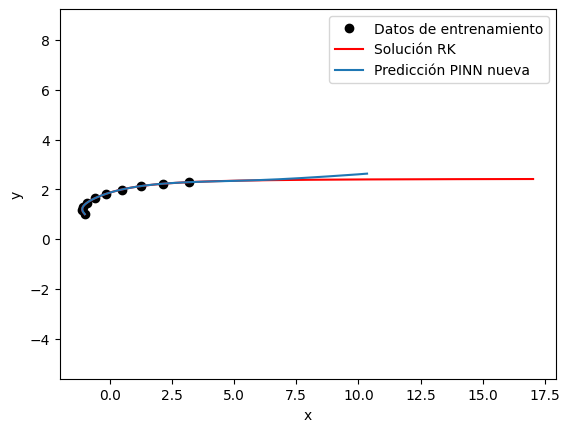

In [ ]:
X_pred_2 = pinn_2(T_pred)
x_pred_2 = X_pred_2.detach().cpu().numpy()

plt.plot(x_train[:,0], x_train[:, 1], "ko", label='Datos de entrenamiento')
plt.plot(x_sol[:,0], x_sol[:, 1], "r-", label='Solución RK')
plt.plot(x_pred_2[:,0], x_pred_2[:, 1], label='Predicción PINN nueva')

plt.xlabel('x')
plt.ylabel('y')
plt.axis('equal')
plt.legend()
plt.show()

Tambien se queda atras, pero pareciera ser por menos. Veamos las coordenadas individuales, comparando con las del entrenamiento de fisica limitado a la primera mitad.

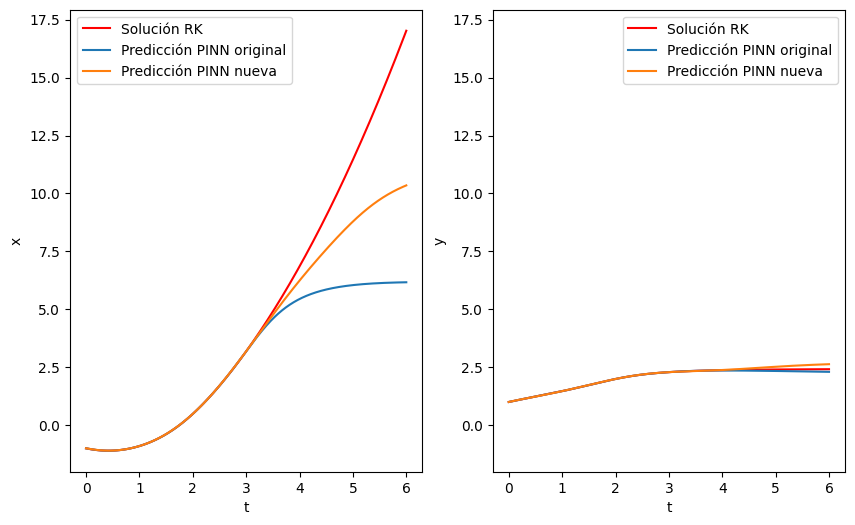

In [ ]:
plt.figure(figsize=(10, 6))

plt.subplot(1,2,1)


plt.plot(t_sol, x_sol[:, 0], "r-", label='Solución RK')
plt.plot(t_sol, x_pred[:, 0], label='Predicción PINN original')
plt.plot(t_sol, x_pred_2[:, 0], label='Predicción PINN nueva')


plt.xlabel('t')
plt.ylabel('x')
plt.legend()

lims = plt.ylim()

plt.subplot(1,2,2)

plt.plot(t_sol, x_sol[:, 1], "r-", label='Solución RK')
plt.plot(t_sol, x_pred[:, 1], label='Predicción PINN original')
plt.plot(t_sol, x_pred_2[:, 1], label='Predicción PINN nueva')


plt.xlabel('t')
plt.ylabel('y')

plt.ylim(lims)

plt.legend()

plt.show()

Se ve que la PINN entrenada con fisica sobre todo el intervalo no llega a predecir toda la trayectoria, pero es una mejora sobre la original para la coordenada x, que es la que tiene la fisica mas compleja.


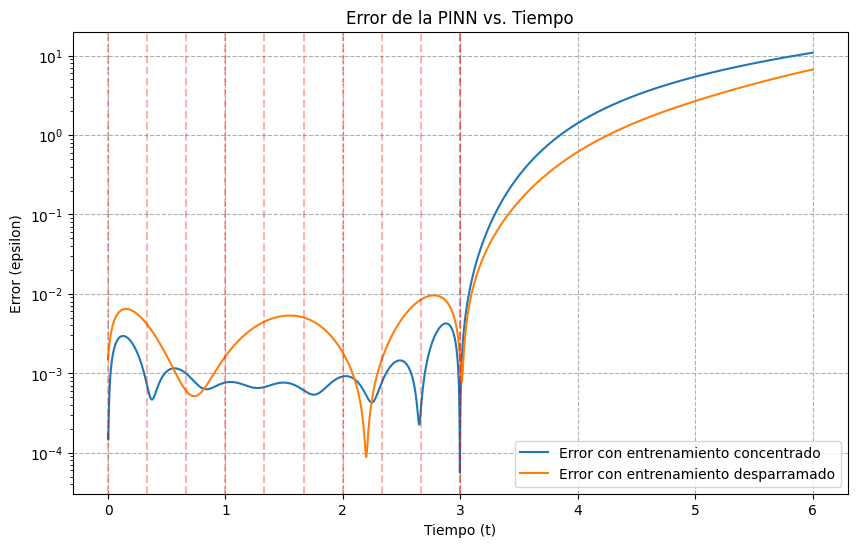

In [ ]:
diferencias_2 = x_pred_2 - x_sol

distancias_2 = np.linalg.norm(diferencias_2, axis=1)


plt.figure(figsize=(10, 6))
plt.plot(t_sol, distancias, label="Error con entrenamiento concentrado")
plt.plot(t_sol, distancias_2, label='Error con entrenamiento desparramado')

plt.xlabel('Tiempo (t)')
plt.ylabel('Error (epsilon)')
plt.title('Error de la PINN vs. Tiempo')
plt.grid(True, linestyle='--')


plt.axvline(x=T, color="red", linestyle="--", alpha=0.3)

for t in t_train:
  plt.axvline(x=t, color="red", linestyle="--", alpha=0.3)


plt.yscale("log")
plt.legend()
plt.show()


El error es un poco mayor en la primera parte, pero bastante menor para $t > 3s$

## Item (iii)

Como no sabemos de antemano durante cuantas epochs estaria bueno entrenar, lo que hacemos es revisar constantemente si la loss es la mejor que tuvimos hasta ahora, y si lo es nos guardamos los parametros, de forma que al final del entrenamiento vamos a tener la mejor version de la red durante el entrenamiento.

Para evitar guardar una version sobreajustada, en vez de ver la loss de una epoch buscamos sobre unas cuantas (asi no consideramos "ruido" como una loss muy chica) y dejamos de guardar si no hubo mejoras en un rato.

Entrenando la red con 2 puntos de entrenamiento con datos


100%|██████████| 20000/20000 [00:50<00:00, 392.71it/s]


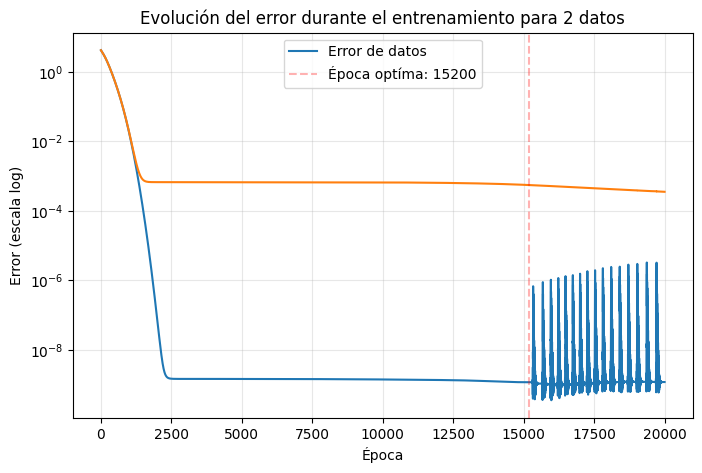

Entrenando la red con 4 puntos de entrenamiento con datos


100%|██████████| 20000/20000 [00:52<00:00, 383.85it/s]


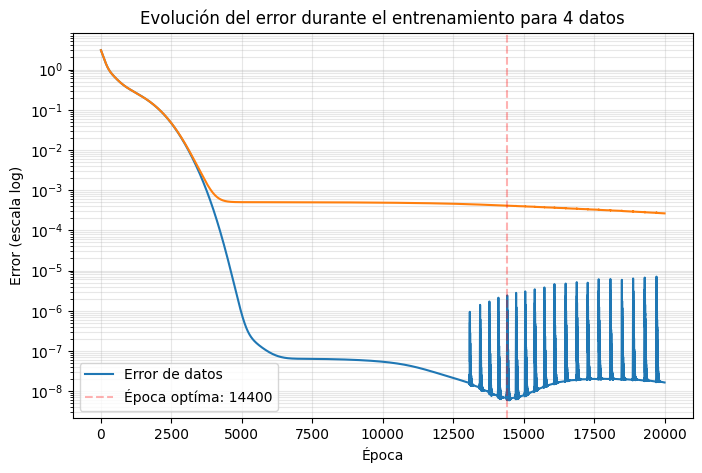

Entrenando la red con 6 puntos de entrenamiento con datos


100%|██████████| 20000/20000 [00:52<00:00, 380.12it/s]


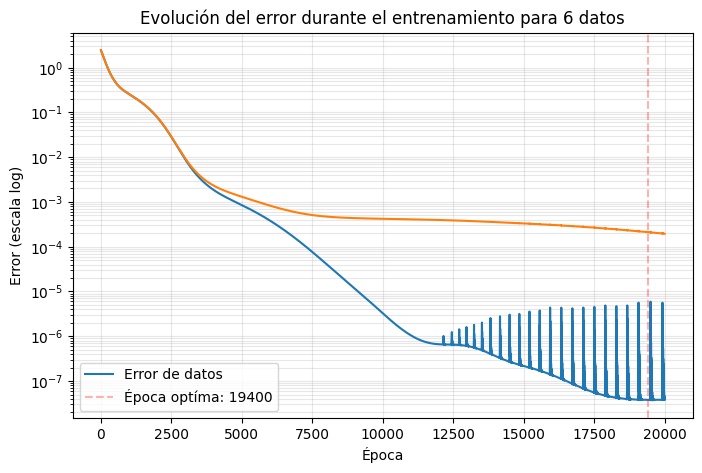

Entrenando la red con 8 puntos de entrenamiento con datos


100%|██████████| 20000/20000 [00:52<00:00, 384.59it/s]


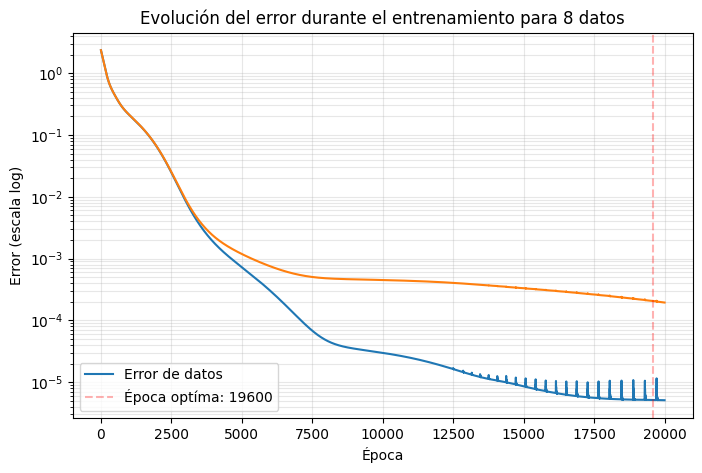

Entrenando la red con 10 puntos de entrenamiento con datos


100%|██████████| 20000/20000 [00:52<00:00, 384.01it/s]


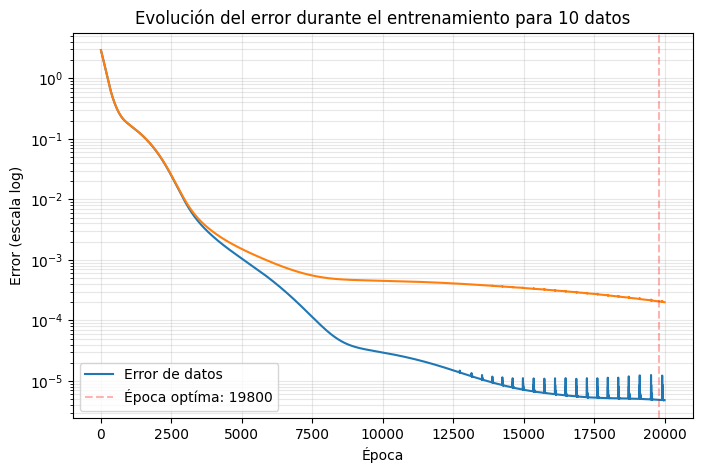

Entrenando la red con 12 puntos de entrenamiento con datos


100%|██████████| 20000/20000 [00:52<00:00, 382.09it/s]


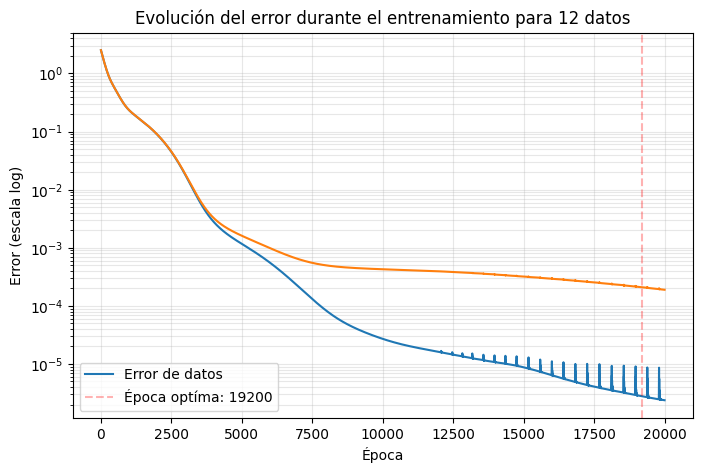

Entrenando la red con 14 puntos de entrenamiento con datos


100%|██████████| 20000/20000 [00:52<00:00, 379.50it/s]


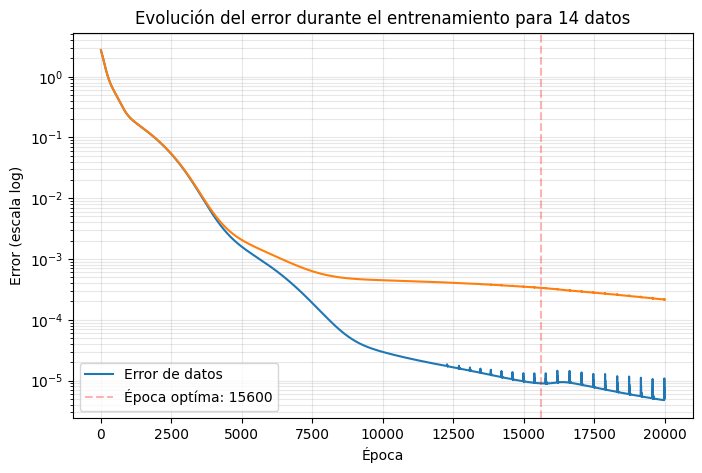

Entrenando la red con 16 puntos de entrenamiento con datos


100%|██████████| 20000/20000 [00:52<00:00, 380.13it/s]


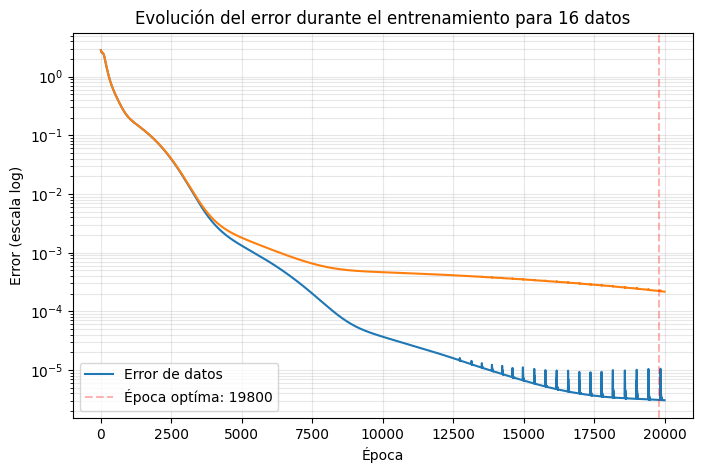

Entrenando la red con 18 puntos de entrenamiento con datos


100%|██████████| 20000/20000 [00:54<00:00, 368.06it/s]


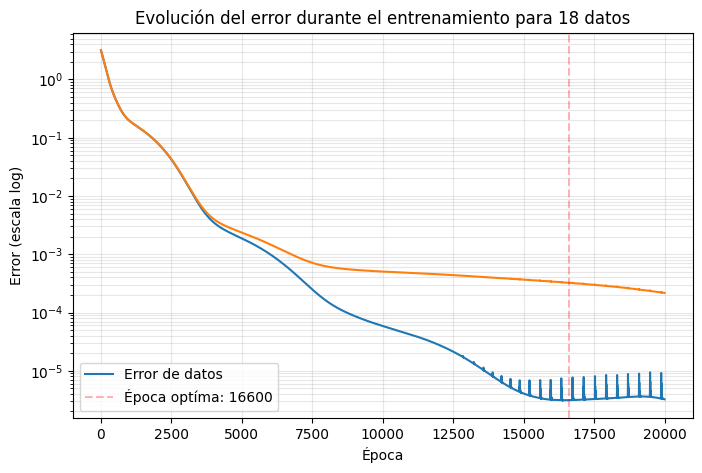

Entrenando la red con 20 puntos de entrenamiento con datos


100%|██████████| 20000/20000 [00:53<00:00, 375.16it/s]


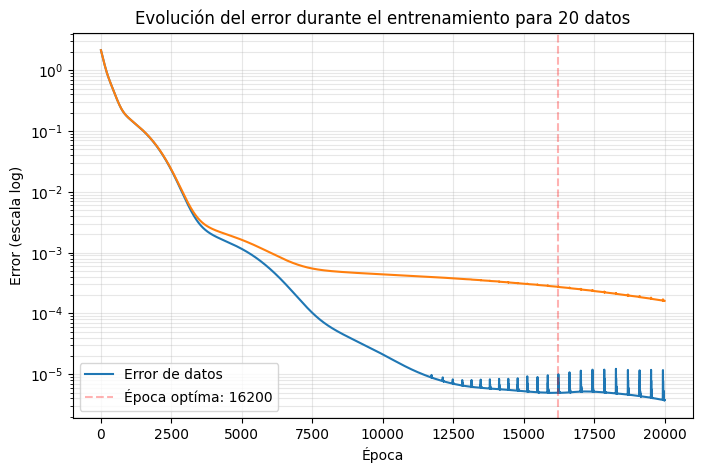

In [ ]:
lista_N_datos = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20]

# Para guardarnos las redes y sus propiedades
lista_pinns = []
lista_mejores_epochs = []
lista_errores = []

# Volvemos a armar el set de datos de fisica
# con puntos en [0, 2T]
N_fisica = 20

paso_fisica = int((n_puntos-1)/(N_fisica-1))

t_fisica = t_sol[0:n_puntos:paso_fisica]

T_fisica = torch.tensor(t_fisica).view(N_fisica,1)

T_fisica.requires_grad = True


for i in range(len(lista_N_datos)):
  N_datos = lista_N_datos[i]

  paso_datos = int(1/2 * (n_puntos-1)/(N_datos-1))

  x_train = x_sol[0:int(n_puntos/2):paso_datos]
  t_train = t_sol[0:int(n_puntos/2):paso_datos]

  X_train = torch.tensor(x_train)
  T_train = torch.tensor(t_train).view(N_datos,1)

  #Definimos la red
  pinn = MLP([1, 32, 32,  2])

  #Implementamos un optimizador
  optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-4)

  epochs = 20000
  l = 1e-4   # Lambda

  historial_loss = np.zeros(epochs)
  historial_mse_datos = np.zeros(epochs)
  historial_mse_fisica = np.zeros(epochs)
  historial_errores = np.zeros(int(epochs/200))

  mejor_epoch = 200 # Como revisamos cada 200 pasos esta es la primera posible
  mejor_error = 10000000000 # numero absurdamente grande
  mejores_pesos = copy.deepcopy(pinn.state_dict())
  overfitting = False

  print("Entrenando la red con " + str(N_datos) + " puntos de entrenamiento con datos")

  for epoch in trange(epochs):
    optimizer.zero_grad() #Borra gradientes de la iteracion anterior

    # El error en las posiciones de entrenamiento
    X_pinn_datos = pinn(T_train)
    MSE_datos = torch.mean((X_pinn_datos - X_train)**2)

    # El error en las velocdiades de entrenamiento
    X_pinn_fisica = pinn(T_fisica)
    dX_dT   = torch.autograd.grad(X_pinn_fisica[:, 0], T_fisica, torch.ones_like(X_pinn_fisica[:, 0]), create_graph=True)[0] # Computamos dx/dt
    dY_dT   = torch.autograd.grad(X_pinn_fisica[:, 1], T_fisica, torch.ones_like(X_pinn_fisica[:, 1]), create_graph=True)[0] # Computamos dy/dt
    U_pinn = torch.concatenate([dX_dT, dY_dT], axis=-1)
    MSE_fisica = torch.mean(( U_pinn - U_entrenamiento(X_pinn_fisica, T_fisica))**2)

    # Ajustamos los pesos de la  red
    loss = MSE_datos + l * MSE_fisica
    loss.backward() #Calcula nuevos gradientes con backpropagation
    optimizer.step() #Actualiza los parámetros en base a sus gradientes

    historial_mse_datos[epoch] = MSE_datos.item()
    historial_mse_fisica[epoch] = MSE_fisica.item()

    # Queremos quedarnos con los mejores parametros, que pueden no ser los del final del entrenamiento
    # Vamos guardando los parametros que consiguieron la mejor loss hasta ahora
    if epoch % 200 == 0 and overfitting == False and epoch > 0:

      if np.max(historial_mse_datos[epoch-199:epoch]) < mejor_error:
        mejores_pesos = copy.deepcopy(pinn.state_dict())
        mejor_epoch = epoch
        mejor_error =  np.max(historial_mse_datos[epoch-199:epoch])

      # Dejamos de guardar si pasa mucho tiempo sin que mejore
      # para no terminar haciendo overfitting
      if epoch - mejor_epoch > 800:
        overfitting = True


  # Cuando termina el entrenamiento,
  # implementamos los mejores parametros

  pinn.load_state_dict(mejores_pesos)

  # Guardamos la red, cuanto tardo en entrenar y su error
  lista_pinns.append(pinn)
  lista_mejores_epochs.append(mejor_epoch)

  plt.figure(figsize=(8,5))
  plt.plot(historial_mse_datos, label='Error de datos')
  plt.scatter(np.arange(200,epochs+200,200),historial_errores)
  plt.plot(historial_mse_datos + l * historial_mse_fisica)
  plt.axvline(x=mejor_epoch, color="red", linestyle="--", alpha=0.3, label="Época optíma: " + str(mejor_epoch))
  plt.yscale('log')
  plt.xlabel('Época')
  plt.ylabel('Error (escala log)')
  plt.title('Evolución del error durante el entrenamiento para ' + str(N_datos) + " datos" )
  plt.legend()
  plt.grid(True, which='both', alpha=0.3)
  plt.show()

El mínimo de la función de costo (promedio del error sobre los datos de entrenamiento y los datos de física) se alcanza en un tiempo de entrenamiento para el cual existe overfitting en el error de los datos. Se consideró entonces el número de épocas óptimas a aquel correspondiente al mínimo del error de datos previo al overfitting. El mecanismo que define el inicio del overfitting es el siguiente:

- Se calcula el costo maximo de los datos en intervalos de 200 epocas hasta que el valor del mismo presente un aumento sostenido sobre 800 epocas. En ese caso se fijan como parametros optimos de la red aquellos que obtuvieron un costo minimo de los datos hasta el momento previo del aumento.


Graficamos el error contra el tiempo de entrenamiento optimo para cada cantidad de datos,

In [ ]:
!pip install adjustText
import adjustText

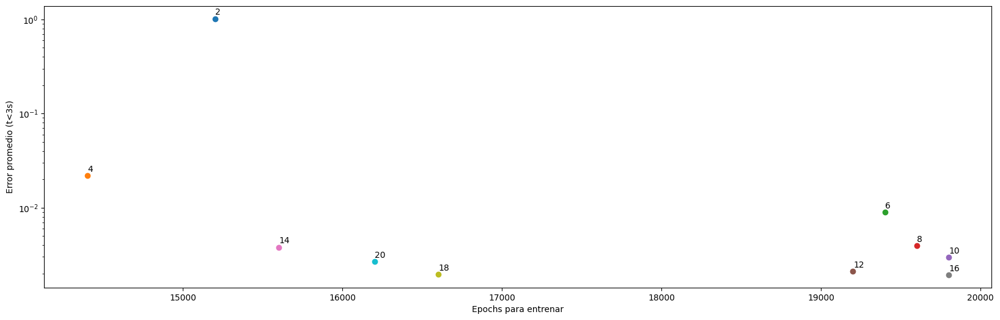

In [ ]:


plt.figure(figsize=(20, 6))

texts = []

for i in range(len(lista_pinns)):

  pinn = lista_pinns[i]
  mejor_epoch = lista_mejores_epochs[i]

  X_pred = pinn(T_pred)
  x_pred = X_pred.detach().cpu().numpy()

  diferencias = x_pred - x_sol

  error_promedio = np.average(np.linalg.norm(diferencias[:int(n_puntos/2)], axis=1))


  # if i == 0 or i == 1:
  #   mejor_epoch = 11000

  plt.scatter(mejor_epoch, error_promedio)
  #plt.annotate(str(lista_N_datos[i])+ " datos", (mejor_epoch, error_promedio))
  texts.append(plt.text(mejor_epoch, error_promedio, str(lista_N_datos[i]), ha='left', va='bottom'))


plt.yscale("log")
plt.xlabel("Epochs para entrenar")
plt.ylabel("Error promedio (t<3s)")

adjustText.adjust_text(texts)

plt.show()

Se observa un comportamiento acotado tanto para el error promedio como para el número de epocas optimas para las redes entrenadas con mas de 6 datos inclusive. Por otro lado, las de 2 y 4 datos se encuentran alejadas de dichos rangos, presentando un error promedio mayor y un entrenamiento más rapido.

Por otro lado, no se puede afirmar que el comportamiento será similar en el caso general, ya que el proceso de entrenamiento es aleatorio y el comportamiento observado es solo un caso de infinitos. Tal vez si se pudieran observar los promedios de muchas realizaciones se verían tendencias o comportamientos más marcados.

Se ve que el tiempo necesario para entrenarlas va aumentando  y se estabiliza cerca de 20000 epochs.

## Item (iv)

Repetimos para varios $N_{fisica}$ diferentes

100%|██████████| 20000/20000 [01:05<00:00, 306.51it/s]


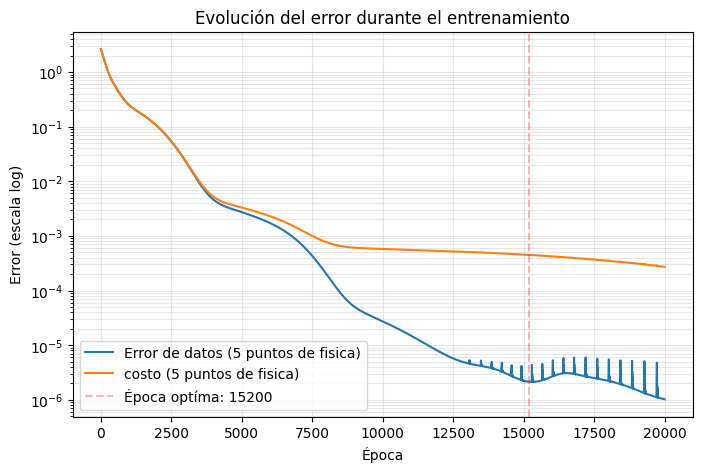

100%|██████████| 20000/20000 [00:56<00:00, 352.39it/s]


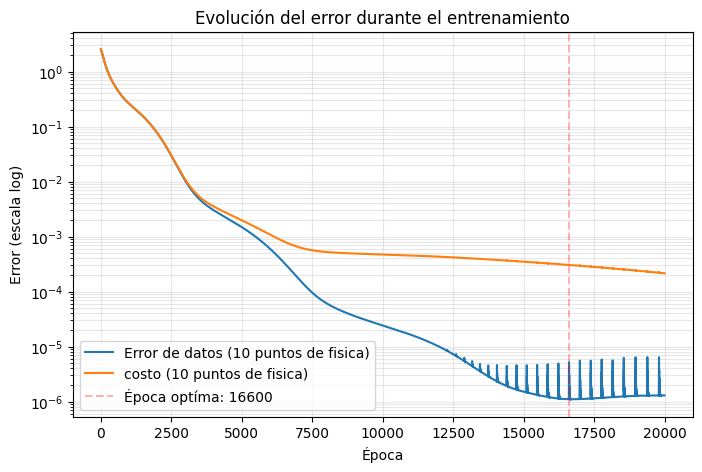

100%|██████████| 20000/20000 [00:58<00:00, 344.44it/s]


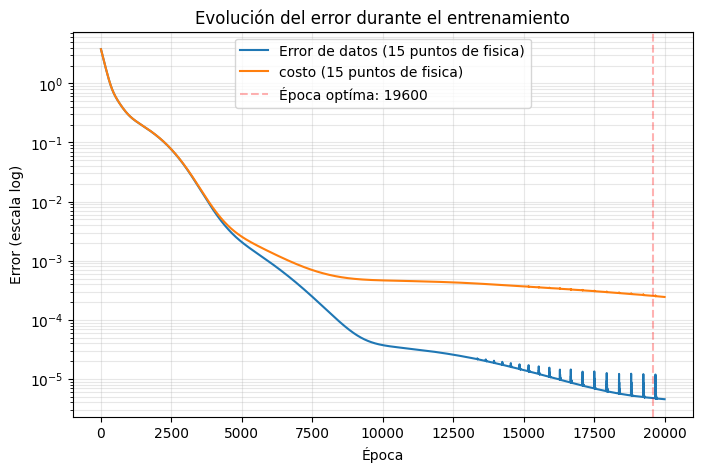

100%|██████████| 20000/20000 [00:58<00:00, 343.89it/s]


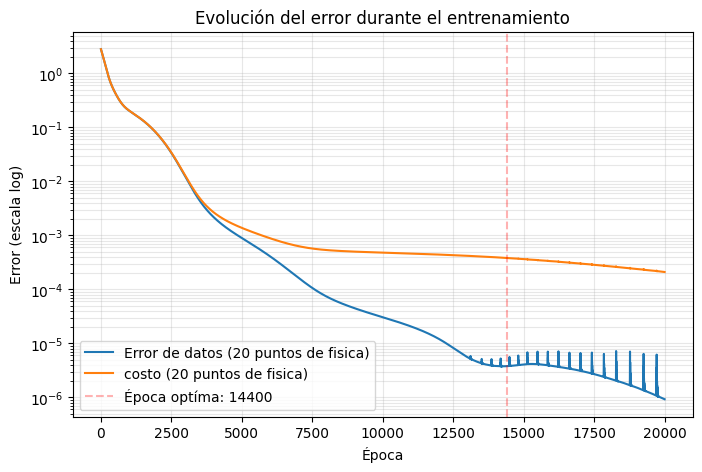

100%|██████████| 20000/20000 [00:59<00:00, 334.53it/s]


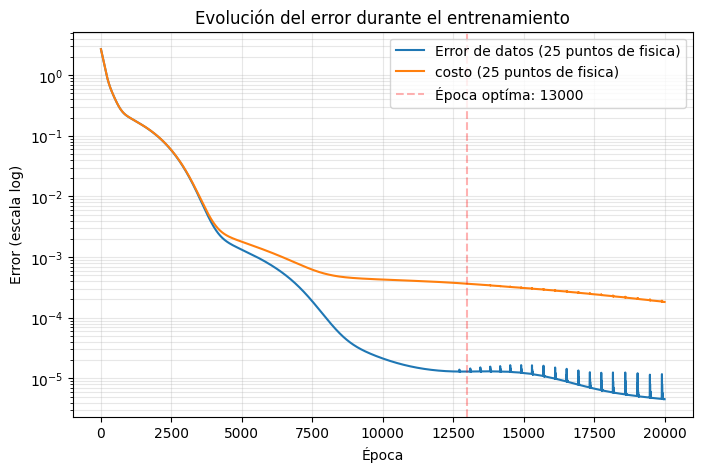

100%|██████████| 20000/20000 [00:59<00:00, 336.32it/s]


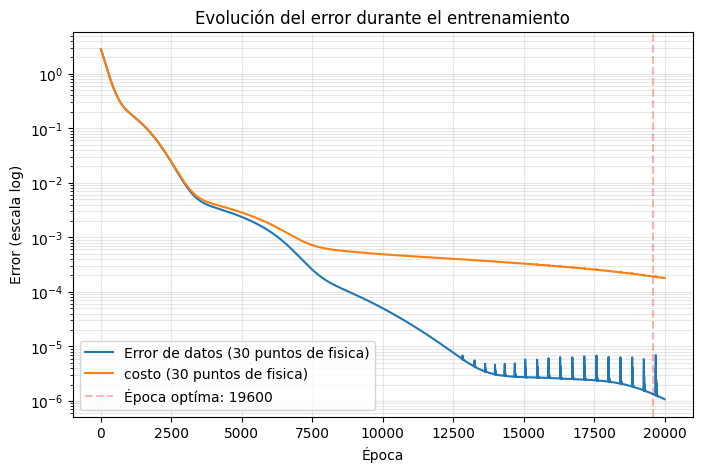

100%|██████████| 20000/20000 [01:01<00:00, 325.84it/s]


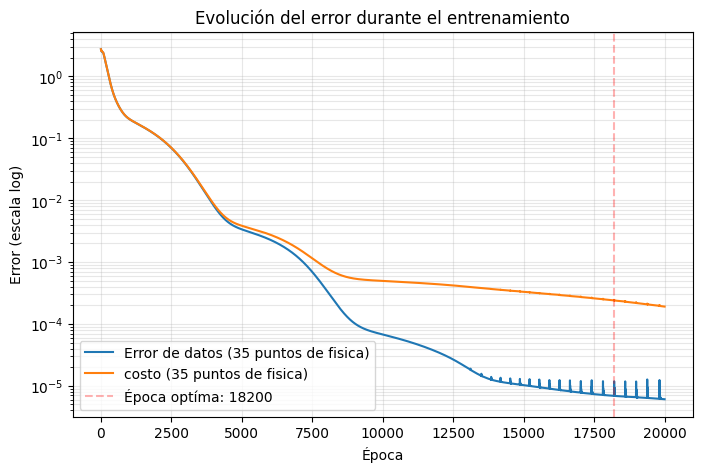

100%|██████████| 20000/20000 [01:00<00:00, 329.23it/s]


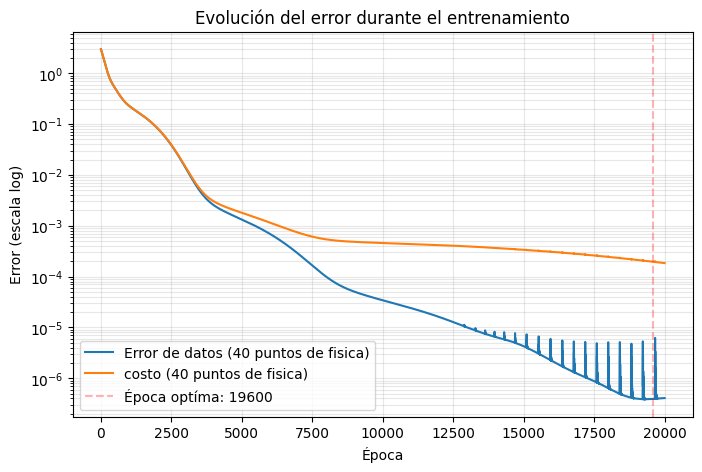

100%|██████████| 20000/20000 [01:02<00:00, 322.08it/s]


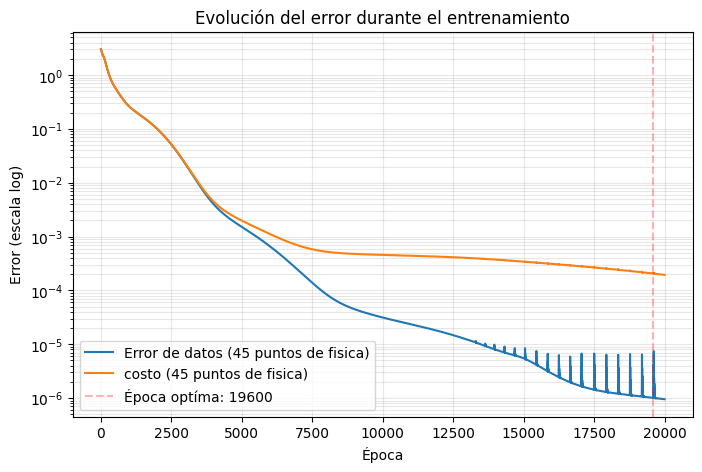

100%|██████████| 20000/20000 [01:02<00:00, 318.15it/s]


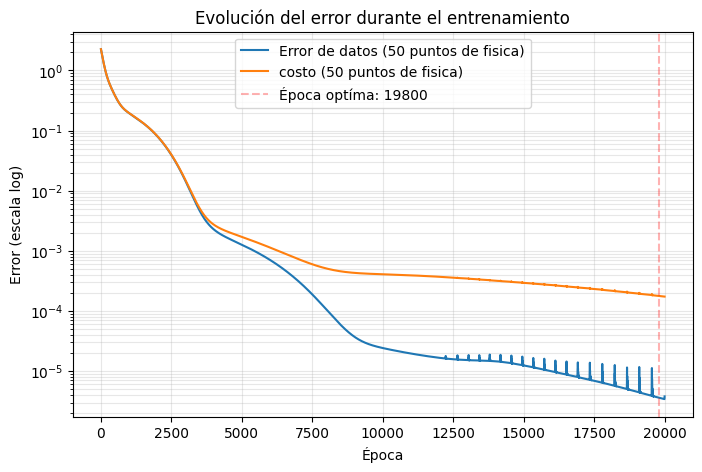

In [ ]:
lista_N_fisica = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]

lista_pinns = []
lista_mejores_epochs = []
lista_errores = []

N_datos = 10

# Preparamos los datos de entrenamiento compartidos
paso_datos = int(1/2 * (n_puntos-1)/(N_datos-1))

x_train = x_sol[0:int(n_puntos/2):paso_datos]
t_train = t_sol[0:int(n_puntos/2):paso_datos]

X_train = torch.tensor(x_train)
T_train = torch.tensor(t_train).view(N_datos,1)


for i in range(len(lista_N_fisica)):
  N_fisica = lista_N_fisica[i]

  paso_fisica = int((n_puntos-1)/(N_fisica-1))

  t_fisica = t_sol[0:n_puntos:paso_fisica]

  T_fisica = torch.tensor(t_fisica).view(N_fisica, 1)

  T_fisica.requires_grad = True


  #Definimos la red
  pinn = MLP([1, 32, 32,  2])

  #Implementamos un optimizador
  optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-4)

  epochs = 20000
  l = 1e-4   # Lambda

  historial_loss = np.zeros(epochs)
  historial_mse_datos = np.zeros(epochs)

  mejor_epoch = 800
  mejor_error = 10000000000
  mejores_pesos = copy.deepcopy(pinn.state_dict())
  overfitting = False

  for epoch in trange(epochs):
    optimizer.zero_grad() #Borra gradientes de la iteracion anterior

    # El error en las posiciones de entrenamiento
    X_pinn_datos = pinn(T_train)
    MSE_datos = torch.mean((X_pinn_datos - X_train)**2)

    # El error en las velocdiades de entrenamiento
    X_pinn_fisica = pinn(T_fisica)
    dX_dT   = torch.autograd.grad(X_pinn_fisica[:, 0], T_fisica, torch.ones_like(X_pinn_fisica[:, 0]), create_graph=True)[0] # Computamos dx/dt
    dY_dT   = torch.autograd.grad(X_pinn_fisica[:, 1], T_fisica, torch.ones_like(X_pinn_fisica[:, 1]), create_graph=True)[0] # Computamos dy/dt
    U_pinn = torch.concatenate([dX_dT, dY_dT], axis=-1)
    MSE_fisica = torch.mean(( U_pinn - U_entrenamiento(X_pinn_fisica, T_fisica))**2)

    # Ajustamos los pesos de la  red
    loss = MSE_datos + l * MSE_fisica
    loss.backward() #Calcula nuevos gradientes con backpropagation
    optimizer.step() #Actualiza los parámetros en base a sus gradientes

    historial_loss[epoch] = loss.item()
    historial_mse_datos[epoch] = MSE_datos.item()
    # Queremos quedarnos con los mejores parametros, que pueden no ser los del final del entrenamiento
    # Vamos guardando los parametros que consiguieron la mejor loss hasta ahora
    if epoch % 200 == 0 and overfitting == False and epoch > 0:

      if np.max(historial_mse_datos[epoch-199:epoch]) < mejor_error:
        mejores_pesos = copy.deepcopy(pinn.state_dict())
        mejor_epoch = epoch
        mejor_error =  np.max(historial_mse_datos[epoch-199:epoch])

      # Dejamos de guardar si pasa mucho tiempo sin que mejore
      # para no terminar haciendo overfitting
      if epoch - mejor_epoch > 800:
        overfitting = True

  # Implementamos los mejores parametros
  pinn.load_state_dict(mejores_pesos)

  # Guardamos la red, cuanto tardo en entrenar y su error
  lista_pinns.append(pinn)
  lista_mejores_epochs.append(mejor_epoch)
  lista_errores.append(historial_loss)

  plt.figure(figsize=(8,5))
  plt.plot(historial_mse_datos, label='Error de datos (' + str(N_fisica) + " puntos de fisica)")
  plt.plot(historial_loss, label='costo (' + str(N_fisica) + " puntos de fisica)")
  plt.axvline(x=mejor_epoch, color="red", linestyle="--", alpha=0.3, label="Época optíma: " + str(mejor_epoch))
  plt.yscale('log')
  plt.xlabel('Época')
  plt.ylabel('Error (escala log)')
  plt.title('Evolución del error durante el entrenamiento')
  plt.legend()
  plt.grid(True, which='both', alpha=0.3)
  plt.show()


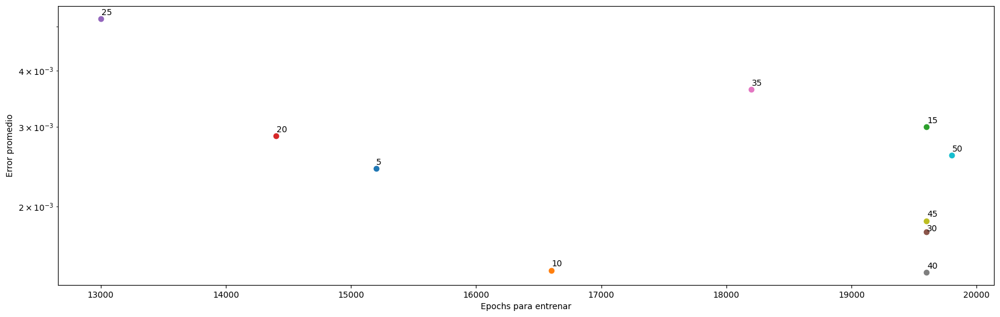

In [ ]:

# fig, ax = plt.subplots()
plt.figure(figsize=(20, 6))
texts = []

for i in range(len(lista_pinns)):
  pinn = lista_pinns[i]
  mejor_epoch = lista_mejores_epochs[i]

  X_pred = pinn(T_pred)
  x_pred = X_pred.detach().cpu().numpy()

  diferencias = x_pred - x_sol

  error_promedio = np.average(np.linalg.norm(diferencias[:int(n_puntos/2)], axis=1))


  plt.scatter(mejor_epoch, error_promedio)
  # plt.annotate(str(lista_N_fisica[i])+ " p. de fisica", (mejor_epoch, error_promedio))
  texts.append(plt.text(mejor_epoch, error_promedio, str(lista_N_fisica[i]), ha='left', va='bottom'))

plt.yscale("log")
plt.xlabel("Epochs para entrenar")
plt.ylabel("Error promedio")

adjustText.adjust_text(texts)

plt.show()

El criterio de seleccion de los parametros considerados optimos es identico al anteriormente utilizado. La razon de esto es que el entrenamiento de fisica es mucho mas lento, por lo que hay overfitting en los datos mucho antes que en la fisica, que en 20000 epocas no llega a aparecer.

Hay una variacion mucho menor en los valores del error promedio y el tiempo de entrenamiento optimo comparado con el inciso anterior. Lo atribuimos a que, como $ \lambda = 10^{-4} $, la fisica tiene un peso mucho menor que los datos de posiciones.

## Item (v)

100%|██████████| 20000/20000 [00:51<00:00, 391.66it/s]


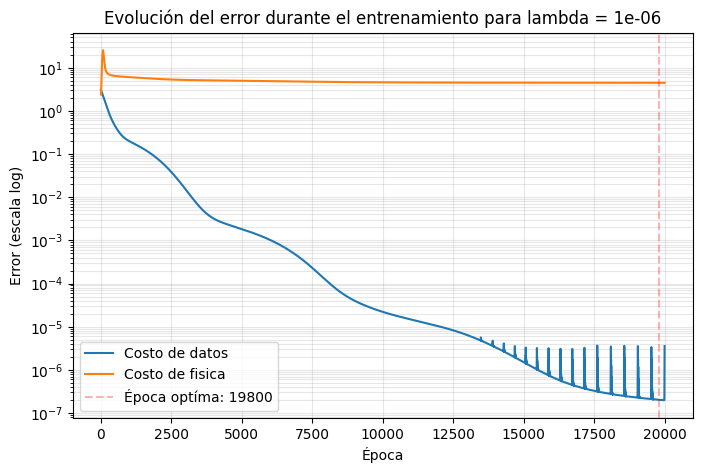

100%|██████████| 20000/20000 [00:59<00:00, 335.42it/s]


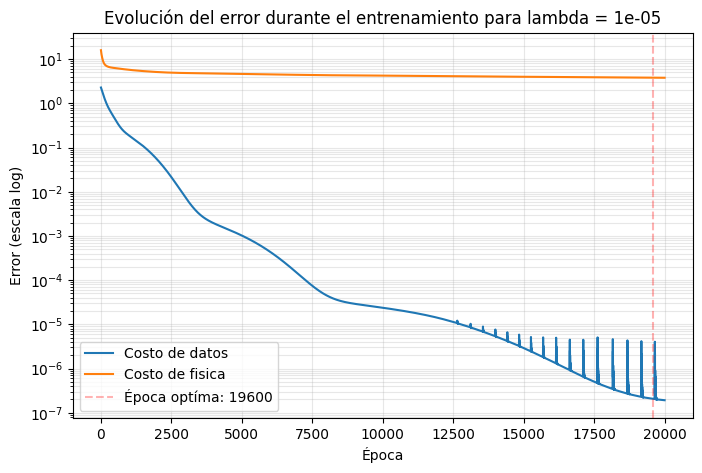

100%|██████████| 20000/20000 [00:59<00:00, 335.82it/s]


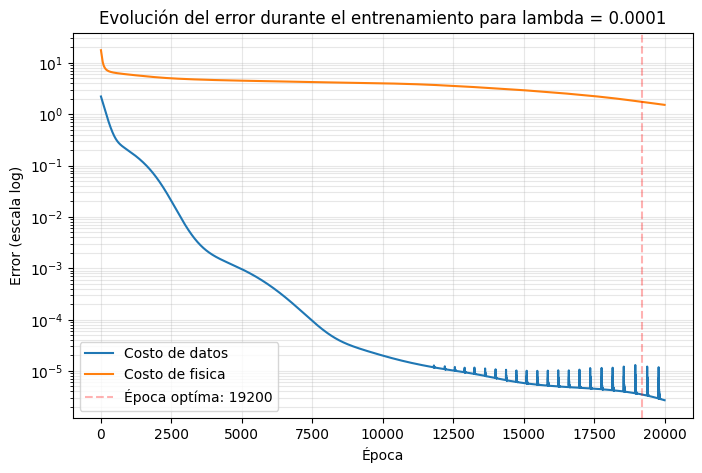

100%|██████████| 20000/20000 [01:00<00:00, 329.08it/s]


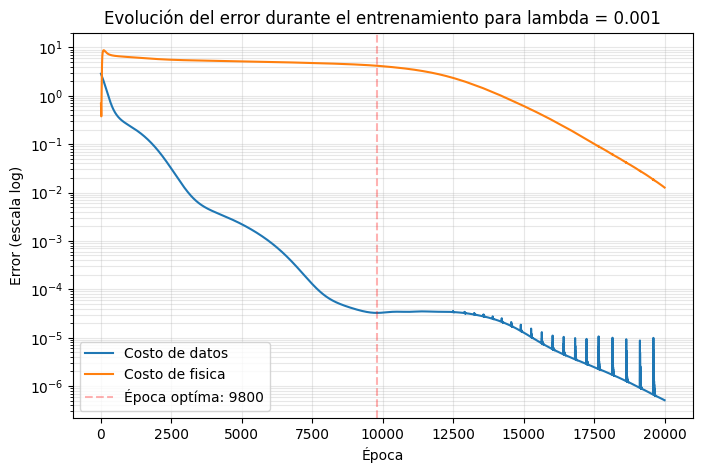

100%|██████████| 20000/20000 [00:59<00:00, 337.42it/s]


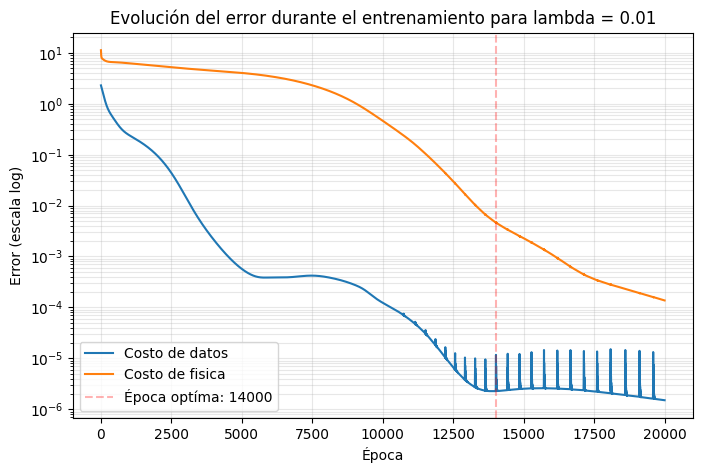

100%|██████████| 20000/20000 [00:54<00:00, 368.18it/s]


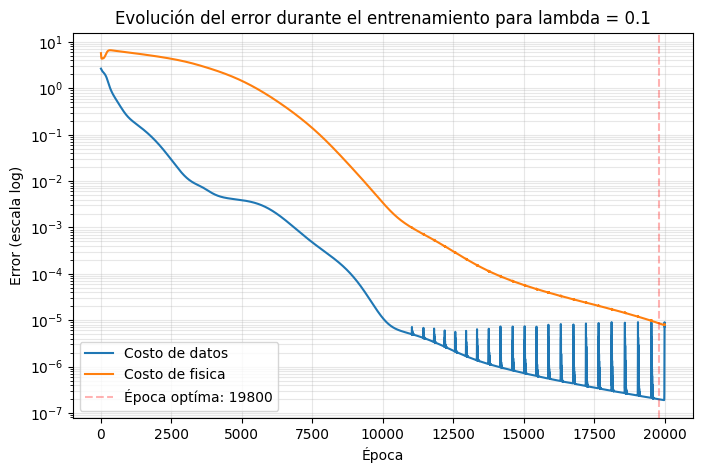

In [ ]:
lista_lambda = np.logspace(-6, -1, 6)

lista_pinns = []
lista_mejores_epochs = []
lista_errores = []

N_datos = 10
N_fisica = 20

# Preparamos los datos de entrenamiento compartidos
paso_datos = int(1/2 * (n_puntos-1)/(N_datos-1))

x_train = x_sol[0:int(n_puntos/2):paso_datos]
t_train = t_sol[0:int(n_puntos/2):paso_datos]

X_train = torch.tensor(x_train)
T_train = torch.tensor(t_train).view(N_datos,1)


paso_fisica = int((n_puntos-1)/(N_fisica-1))

t_fisica = t_sol[0:n_puntos:paso_fisica]

T_fisica = torch.tensor(t_fisica).view(N_fisica,1)

T_fisica.requires_grad = True

for i in range(len(lista_lambda)):

  #Definimos la red
  pinn = MLP([1, 32, 32,  2])

  #Implementamos un optimizador
  optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-4)

  epochs = 20000
  l = lista_lambda[i]

  historial_loss = np.zeros(epochs)
  historial_mse_datos = np.zeros(epochs)
  historial_mse_fisica = np.zeros(epochs)

  mejor_epoch = 800
  mejor_error = 10000000000
  mejores_pesos = copy.deepcopy(pinn.state_dict())
  overfitting = False

  for epoch in trange(epochs):
    optimizer.zero_grad() #Borra gradientes de la iteracion anterior

    # El error en las posiciones de entrenamiento
    X_pinn_datos = pinn(T_train)
    MSE_datos = torch.mean((X_pinn_datos - X_train)**2)

    # El error en las velocdiades de entrenamiento
    X_pinn_fisica = pinn(T_fisica)
    dX_dT   = torch.autograd.grad(X_pinn_fisica[:, 0], T_fisica, torch.ones_like(X_pinn_fisica[:, 0]), create_graph=True)[0] # Computamos dx/dt
    dY_dT   = torch.autograd.grad(X_pinn_fisica[:, 1], T_fisica, torch.ones_like(X_pinn_fisica[:, 1]), create_graph=True)[0] # Computamos dy/dt
    U_pinn = torch.concatenate([dX_dT, dY_dT], axis=-1)
    MSE_fisica = torch.mean(( U_pinn - U_entrenamiento(X_pinn_fisica, T_fisica))**2)

    # Ajustamos los pesos de la  red
    loss = MSE_datos + l * MSE_fisica
    loss.backward() #Calcula nuevos gradientes con backpropagation
    optimizer.step() #Actualiza los parámetros en base a sus gradientes

    historial_loss[epoch] = loss.item()
    historial_mse_datos[epoch] = MSE_datos.item()
    historial_mse_fisica[epoch] = MSE_fisica.item()
    # Queremos quedarnos con los mejores parametros, que pueden no ser los del final del entrenamiento
    # Vamos guardando los parametros que consiguieron la mejor loss hasta ahora
    if epoch % 200 == 0 and overfitting == False and epoch > 0:

      if np.max(historial_mse_datos[epoch-199:epoch]) < mejor_error:
        mejores_pesos = copy.deepcopy(pinn.state_dict())
        mejor_epoch = epoch
        mejor_error =  np.max(historial_mse_datos[epoch-199:epoch])

      # Dejamos de guardar si pasa mucho tiempo sin que mejore
      # para no terminar haciendo overfitting
      if l != 0.01 and epoch - mejor_epoch > 800:
        overfitting = True
      if (l==0.1 or l == 0.01 or l == 0.001) and epoch - mejor_epoch > 800 and epoch > 10000:
        overfitting = True

  # Implementamos los mejores parametros
  pinn.load_state_dict(mejores_pesos)

  # Guardamos la red, cuanto tardo en entrenar y su error
  lista_pinns.append(pinn)
  lista_mejores_epochs.append(mejor_epoch)
  lista_errores.append(historial_loss)

  plt.figure(figsize=(8,5))
  plt.plot(historial_mse_datos, label='Costo de datos')
  plt.plot(historial_mse_fisica, label='Costo de fisica')
  plt.axvline(x=mejor_epoch, color="red", linestyle="--", alpha=0.3, label="Época optíma: " + str(mejor_epoch))
  plt.yscale('log')
  plt.xlabel('Época')
  plt.ylabel('Error (escala log)')
  plt.title('Evolución del error durante el entrenamiento para lambda = ' + str(l))
  plt.legend()
  plt.grid(True, which='both', alpha=0.3)
  plt.show()

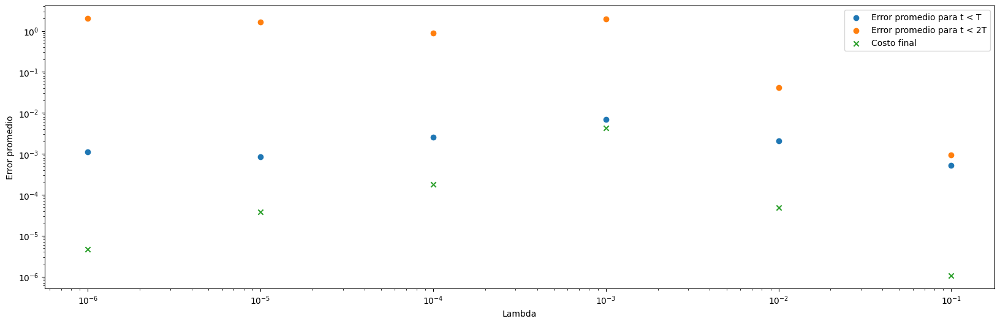

In [ ]:
plt.figure(figsize=(20, 6))
lista_errores_promedios = np.zeros(len(lista_pinns))
lista_errores_promedios_tot = np.zeros(len(lista_pinns))

for i in range(len(lista_pinns)):
  pinn = lista_pinns[i]
  l = lista_lambda[i]
  mejor_epoch = lista_mejores_epochs[i]

  X_pred = pinn(T_pred)
  x_pred = X_pred.detach().cpu().numpy()

  diferencias = x_pred - x_sol

  error_promedio = np.average(np.linalg.norm(diferencias[:int(n_puntos/2)], axis=1))
  error_promedio_tot = np.average(np.linalg.norm(diferencias[:int(n_puntos)], axis=1))

  lista_errores_promedios[i] = error_promedio
  lista_errores_promedios_tot[i] = error_promedio_tot

plt.scatter(lista_lambda, lista_errores_promedios, label="Error promedio para t < T")
plt.scatter(lista_lambda, lista_errores_promedios_tot, label="Error promedio para t < 2T")
plt.scatter(lista_lambda, [lista_errores[i][lista_mejores_epochs[i]] for i in range(len(lista_lambda))], label="Costo final", marker ='x')

plt.yscale("log")
plt.xscale("log")
plt.xlabel("Lambda")
plt.ylabel("Error promedio")
plt.legend()
plt.show()

Al considerar el error del promedio hasta el tiempo de entrenamiento $T$, vemos que no varia con $\lambda$, lo que indica que el peso del costo de la fisica no es relevante para la capacidad de la red de aprender la parte de la trayectoria sobre la que tiene datos concretos. Sin embargo, para $\lambda = 10^{-2}$ hay una disminucion abrupta del error sobre el intervalo $[0,2T]$, asi tambien como una caida del valor final de la funcion de costo. Por otro lado, se ve un aumento sostenido del valor del costo final a medida que aumenta $\lambda$ (hasta $\lambda = 10^{-2}$).

Una posible explicaicon de la tendencia creciente del costo para $\lambda$ chico es que el costo de fisica no varia, pero cada vez tiene un peso mayor en la funcion de costo. Esto implicaria que las redes son incapaces de aprender correctamente la fisica hasta cierto valor minimo de $\lambda$.

## Item (vi)

Entrenando la red [1, 8, 2]


100%|██████████| 20000/20000 [01:00<00:00, 331.64it/s]


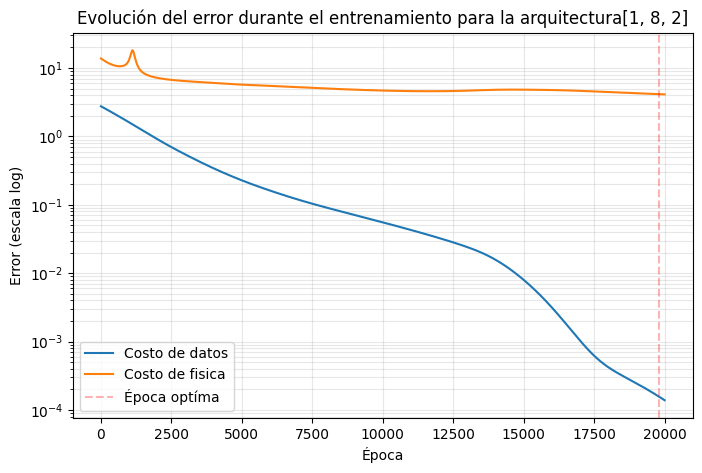

Entrenando la red [1, 16, 2]


100%|██████████| 20000/20000 [01:00<00:00, 328.99it/s]


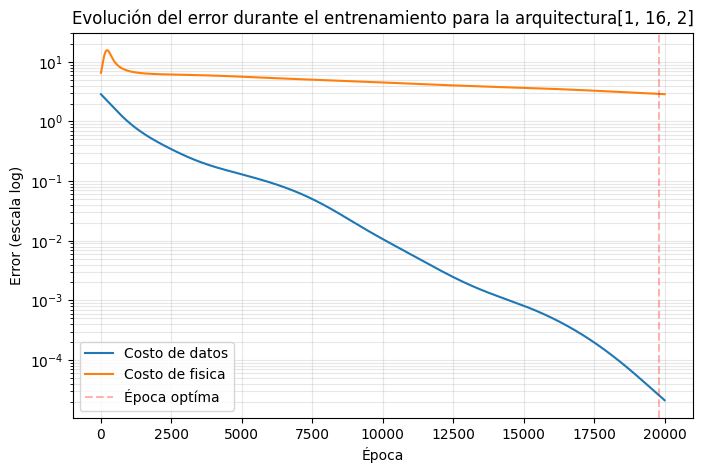

Entrenando la red [1, 32, 2]


100%|██████████| 20000/20000 [00:59<00:00, 333.59it/s]


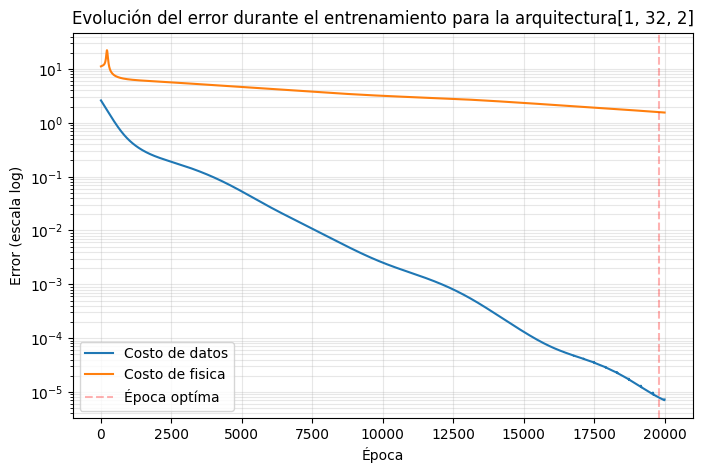

Entrenando la red [1, 16, 16, 2]


100%|██████████| 20000/20000 [01:16<00:00, 260.89it/s]


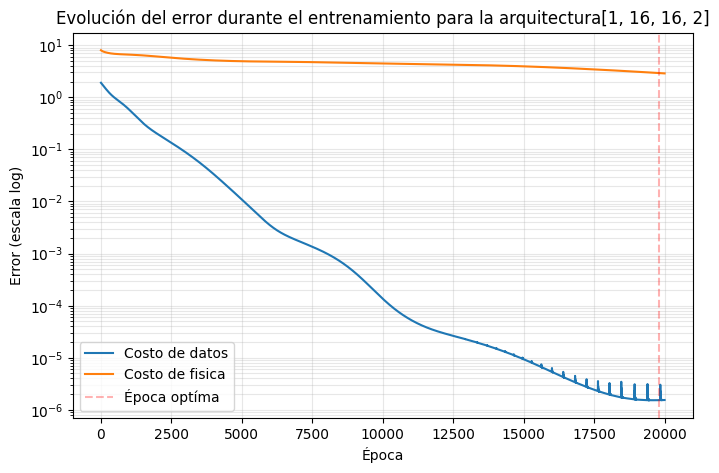

Entrenando la red [1, 32, 32, 2]


100%|██████████| 20000/20000 [01:20<00:00, 247.58it/s]


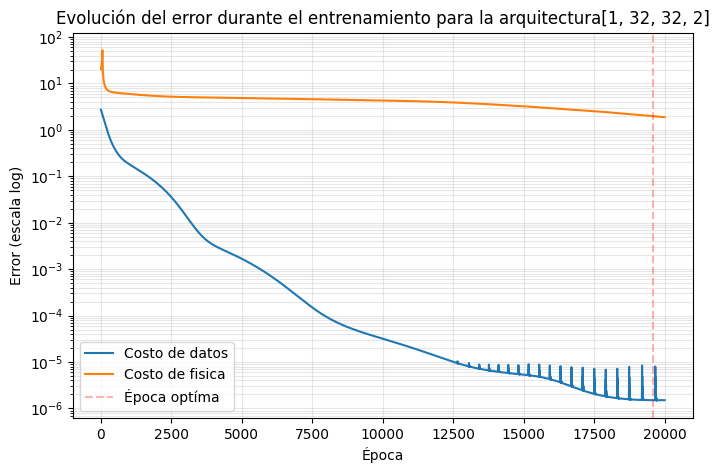

Entrenando la red [1, 64, 64, 2]


100%|██████████| 20000/20000 [01:22<00:00, 243.25it/s]


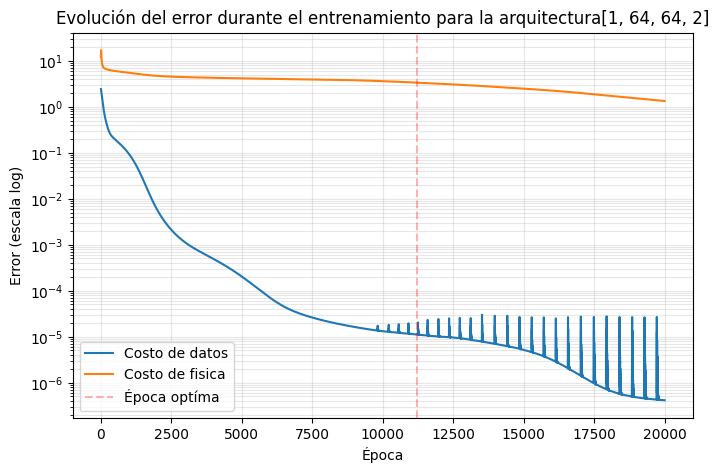

Entrenando la red [1, 16, 16, 16, 2]


100%|██████████| 20000/20000 [01:29<00:00, 224.39it/s]


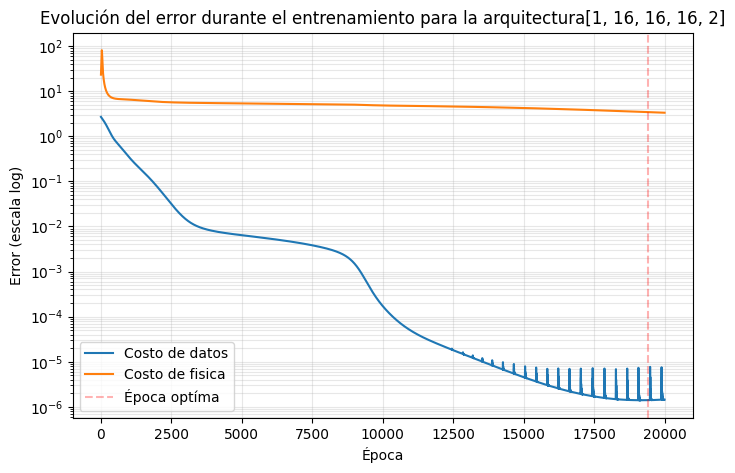

Entrenando la red [1, 32, 32, 32, 2]


100%|██████████| 20000/20000 [01:33<00:00, 213.84it/s]


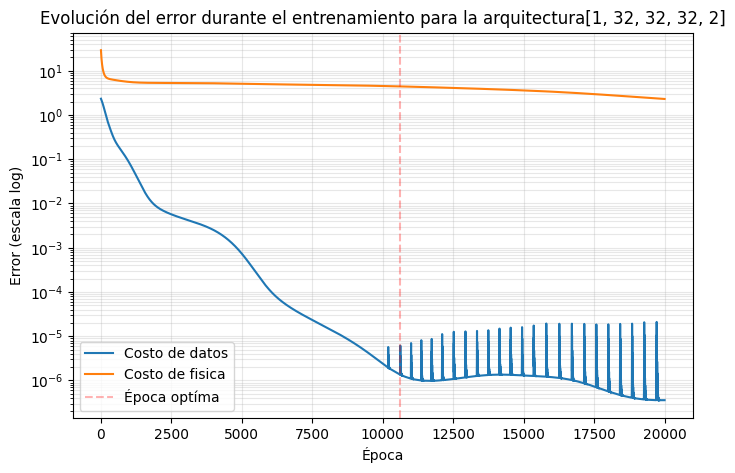

In [ ]:
lista_arquitecturas = [
    [1, 8, 2],
    [1, 16, 2],
    [1, 32, 2],
    [1, 16, 16, 2],
    [1, 32, 32, 2],
    [1, 64, 64, 2],
    [1, 16, 16, 16, 2],
    [1, 32, 32, 32, 2],
]

# Para guardarnos las redes y sus propiedades
lista_pinns = []
lista_mejores_epochs = []
lista_errores = []

N_datos = 10

# Preparamos los datos de entrenamiento compartidos
paso_datos = int((n_puntos/2-1)/(N_datos-1))

x_train = x_sol[0:int(n_puntos/2):paso_datos]
t_train = t_sol[0:int(n_puntos/2):paso_datos]

X_train = torch.tensor(x_train)
T_train = torch.tensor(t_train).view(N_datos,1)


# Volvemos a armar el set de datos de fisica
# con puntos en [0, 2T]
N_fisica = 20

paso_fisica = int((n_puntos-1)/(N_fisica-1))

t_fisica = t_sol[0:n_puntos:paso_fisica]

T_fisica = torch.tensor(t_fisica).view(N_fisica,1)

T_fisica.requires_grad = True


for i in range(len(lista_arquitecturas)):
  arquitectura = lista_arquitecturas[i]
  pinn = MLP(arquitectura)

  #Implementamos un optimizador
  optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-4)

  epochs = 20000
  l = 1e-4   # Lambda

  historial_loss = np.zeros(epochs)
  historial_mse_datos = np.zeros(epochs)
  historial_mse_fisica = np.zeros(epochs)
  historial_errores = np.zeros(int(epochs/200))

  mejor_epoch = 200 # Como revisamos cada 200 pasos esta es la primera posible
  mejor_error = 10000000000 # numero absurdamente grande
  mejores_pesos = copy.deepcopy(pinn.state_dict())
  overfitting = False

  print("Entrenando la red " + str(arquitectura))

  for epoch in trange(epochs):
    optimizer.zero_grad() #Borra gradientes de la iteracion anterior

    # El error en las posiciones de entrenamiento
    X_pinn_datos = pinn(T_train)
    MSE_datos = torch.mean((X_pinn_datos - X_train)**2)

    # El error en las velocdiades de entrenamiento
    X_pinn_fisica = pinn(T_fisica)
    dX_dT   = torch.autograd.grad(X_pinn_fisica[:, 0], T_fisica, torch.ones_like(X_pinn_fisica[:, 0]), create_graph=True)[0] # Computamos dx/dt
    dY_dT   = torch.autograd.grad(X_pinn_fisica[:, 1], T_fisica, torch.ones_like(X_pinn_fisica[:, 1]), create_graph=True)[0] # Computamos dy/dt
    U_pinn = torch.concatenate([dX_dT, dY_dT], axis=-1)
    MSE_fisica = torch.mean(( U_pinn - U_entrenamiento(X_pinn_fisica, T_fisica))**2)

    # Ajustamos los pesos de la  red
    loss = MSE_datos + l * MSE_fisica
    loss.backward() #Calcula nuevos gradientes con backpropagation
    optimizer.step() #Actualiza los parámetros en base a sus gradientes

    historial_mse_datos[epoch] = MSE_datos.item()
    historial_mse_fisica[epoch] = MSE_fisica.item()

    # Queremos quedarnos con los mejores parametros, que pueden no ser los del final del entrenamiento
    # Vamos guardando los parametros que consiguieron la mejor loss hasta ahora
    if epoch % 200 == 0 and overfitting == False and epoch > 0:

      if np.max(historial_mse_datos[epoch-199:epoch]) < mejor_error:
        mejores_pesos = copy.deepcopy(pinn.state_dict())
        mejor_epoch = epoch
        mejor_error =  np.max(historial_mse_datos[epoch-100:epoch])

      # Dejamos de guardar si pasa mucho tiempo sin que mejore
      # para no terminar haciendo overfitting
      if epoch - mejor_epoch > 600:
        overfitting = True


  # Cuando termina el entrenamiento,
  # implementamos los mejores parametros

  pinn.load_state_dict(mejores_pesos)

  # Guardamos la red, cuanto tardo en entrenar y su error
  lista_pinns.append(pinn)
  lista_mejores_epochs.append(mejor_epoch)

  plt.figure(figsize=(8,5))
  plt.plot(historial_mse_datos, label='Costo de datos')
  #plt.scatter(np.arange(200,epochs+200,200),historial_errores)
  plt.plot(historial_mse_fisica, label="Costo de fisica")
  plt.axvline(x=mejor_epoch, color="red", linestyle="--", alpha=0.3, label="Época optíma")
  plt.yscale('log')
  plt.xlabel('Época')
  plt.ylabel('Error (escala log)')
  plt.title('Evolución del error durante el entrenamiento para la arquitectura' + str(arquitectura))
  plt.legend()
  plt.grid(True, which='both', alpha=0.3)
  plt.show()

Como adicional a la actividad, se intento una arquitectura completamente diferente para el modelo: un polinomio de Fourier, cuyos coeficientes se entrenan de igual manera que las neuronas de las redes para minimizar el costo de datos y fisica.

In [ ]:
class Fourier(torch.nn.Module):
  def __init__(self,sizes):
    super().__init__()

    self.grado = sizes[0]
    # Como es un movimiento 2d, tenemos pares de parametros. k=1,2
    self.a = torch.nn.Parameter(torch.randn(self.grado, 2)) # En indices a_jk
    self.b = torch.nn.Parameter(torch.randn(self.grado, 2)) # En indices b_jk
    self.c = torch.nn.Parameter(torch.rand(2)) # Un termino lineal c_k

    # Periodo 2T
    self.frecuencias = torch.pi / T * torch.arange(self.grado) # En indices w_j

  def forward(self, input):
    # Usamos la notacion de einstein para hacer la suma
    # x_k = c_k t + a_j k cos(w_j t) + b_j k sin(w_j t)
    t = input.view(-1)               # En indices, t_i
    wt = torch.einsum("i, j",t, self.frecuencias)   # En indices, t_i w_j

    termino_cos = torch.einsum("i j, j k", torch.cos(wt), self.a) # cos(t_i w_j) a_j k
    termino_sin = torch.einsum("ia j, j k", torch.sin(wt), self.b) # sin(t_i w_j) b_j k
    termino_lineal = torch.einsum("i, k", t, self.c)              # t_i c_k

    # El resultado final tiene dos indices: i da el tiempo, y k da si es la componente x o y.
    return termino_cos + termino_sin + termino_lineal

In [ ]:
N_datos = 10
N_fisica = 20

# Sacamos los datos solo de la primera mitad de la trayectoria
paso_datos = int(1/2 * (n_puntos-1)/(N_datos-1))
paso_fisica = int((n_puntos-1)/(N_fisica-1))

x_train = x_sol[0:int(n_puntos/2):paso_datos]
t_train = t_sol[0:int(n_puntos/2):paso_datos]

# Y los de fisica de la trayectoria entera
t_fisica = t_sol[0:n_puntos:paso_fisica]


# Las pasamos a tensores de torch
X_train = torch.tensor(x_train)
T_train = torch.tensor(t_train).view(N_datos, 1)
T_fisica = torch.tensor(t_fisica).view(N_fisica,1)

#Definimos la red
fourier = Fourier([10])

#Implementamos un optimizador
optimizer = torch.optim.Adam(fourier.parameters(), lr=1e-2)

epochs = 15000
l = 1e-4   # Lambda


# Vamos a querer derivar respecto al tensor de tiempos de
# fisica para sacar la velocidad
T_fisica.requires_grad = True

for epoch in trange(epochs):
    optimizer.zero_grad() #Borra gradientes de la iteracion anterior

    # Error en las posiciones de entrenamiento
    X_pinn_datos = fourier(T_train)
    MSE_datos = torch.mean((X_pinn_datos - X_train)**2)

    # Error en las velocdiades de entrenamiento
    X_pinn_fisica = fourier(T_fisica)
    dX_dT   = torch.autograd.grad(X_pinn_fisica[:, 0], T_fisica, torch.ones_like(X_pinn_fisica[:, 0]), create_graph=True)[0]
    dY_dT   = torch.autograd.grad(X_pinn_fisica[:, 1], T_fisica, torch.ones_like(X_pinn_fisica[:, 1]), create_graph=True)[0]
    U_pinn = torch.concatenate([dX_dT, dY_dT], axis=-1)
    MSE_fisica = torch.mean(( U_pinn - U_entrenamiento(X_pinn_fisica, T_fisica))**2)

    # Ajustamos los pesos de la  red
    loss = MSE_datos + l * MSE_fisica
    loss.backward() #Calcula nuevos gradientes con backpropagation
    optimizer.step() #Actualiza los parámetros en base a sus gradientes

100%|██████████| 15000/15000 [00:45<00:00, 326.81it/s]


/tmp/ipykernel_1233/2798299467.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


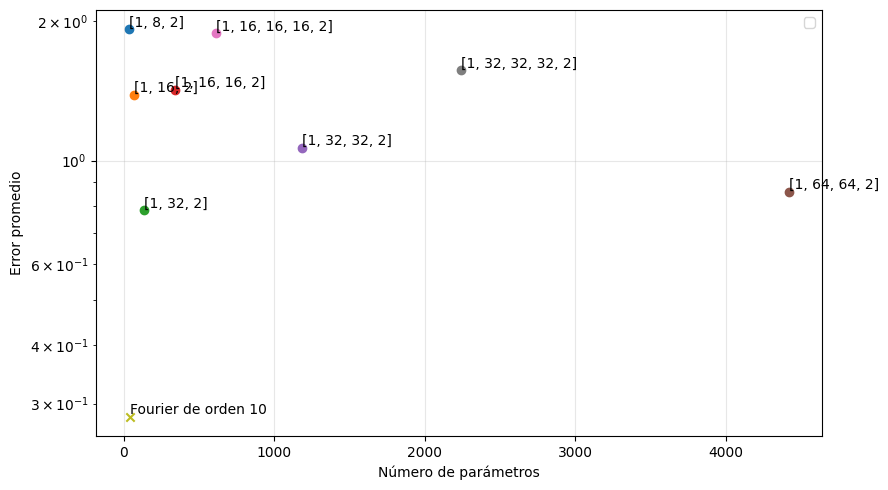

In [ ]:
plt.figure(figsize=(9, 5))
lista_errores_promedios = np.zeros(len(lista_pinns))

texts = []

for i in range(len(lista_pinns)):
  pinn = lista_pinns[i]
  mejor_epoch = lista_mejores_epochs[i]

  X_pred = pinn(T_pred)
  x_pred = X_pred.detach().cpu().numpy()

  diferencias = x_pred - x_sol

  error_promedio = np.average(np.linalg.norm(diferencias[:n_puntos], axis=1))

  lista_errores_promedios[i] = error_promedio
  plt.scatter(sum(p.numel() for p in pinn.parameters()), error_promedio)
  texts.append(plt.text(sum(p.numel() for p in pinn.parameters()), error_promedio, str(lista_arquitecturas[i]), ha='left', va='bottom'))

X_pred = fourier(T_pred)
x_pred = X_pred.detach().cpu().numpy()

diferencias = x_pred - x_sol

error_promedio = np.average(np.linalg.norm(diferencias[:n_puntos], axis=1))

lista_errores_promedios[i] = error_promedio
plt.scatter(sum(p.numel() for p in fourier.parameters()), error_promedio, marker="x")
texts.append(plt.text(sum(p.numel() for p in fourier.parameters()), error_promedio, "Fourier de orden 10", ha='left', va='bottom'))

plt.xlabel('Número de parámetros')
plt.ylabel('Error promedio')
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.legend()
plt.show()

Se observa en la figura el error medio (calculado sobre el intervalo $[0,2T]$) para distintas arquitecturas de la red. Se agrego ademas el error correspondiente al modelo de Fourier de orden 10. Observamos que para las redes neuronales, aumentar el numero de parametros manteniendo la cantidad de capas constante disminuye el error promedio. Asimismo vemos que la alternativa propuesta requiere menor numero de parametros para lograr un error considerablemente mejor.

# Problema 3

Un grupo de Laboratorio 5 elige hacer la mejor práctica de la materia: Fluidos.
En esta práctica, se introduce un agitador magnético para generar un vórtice dentro de un recipiente cilíndrico y se usa el método velocimetría de imágenes de partículas (PIV, por sus siglas en inglés).
Esto permite medir el campo de velocidades $\mathbf{u}(\mathbf{x}, t)$ sobre la superficie, habitualmente modelado mediante el vórtice de Burgers
$$ \mathbf{u}_B(\mathbf{x}, t) = -\alpha r \mathbf{\hat{r}} + \frac{\Gamma}{2\pi r}\left[1 - \exp\left(-r^2/r_0^2\right)\right]\boldsymbol{\hat{\theta}} + 2\alpha z\mathbf{\hat{z}} $$
donde $\Gamma$ es la circulación asintótica del vórtice, $\alpha$ un parámetro que controla el flujo radial y $r_0 = \alpha / 2\nu$ un radio característico del vórtice controlado por la velocidad y la viscosidad.
Dado que se mira la superficie, la componente $z$ suele ignorarse por completo.

Sin embargo, las cámaras de alta velocidad necesarias para hacer PIV no funcionan y no pudieron ser reemplazadas por cuestiones presupuestarias. Ante la desesperación, el grupo decide introducir una pequeña bolita de polietileno dentro del flujo y grabarla con un celular.
Luego, el grupo elige algunos de los cuadros del video donde tanto el centro del vórtice cómo la bolita se ven claramente y, muy laboriosamente, determinan la posición relativa de ambos.
Estos datos se encuentran en el archivo `posiciones.txt`, con la posición $\mathbf{X}(t)$ (en cartesianas) de la bolita respecto al vórtice (que se considera en el origen) para los $t$ indicados. Las distancias están medidas en centimetros y el tiempo en segundos.

Entrene una PINN que ajuste la trayectoria mediante el modelo de Burgers $\dot{\mathbf{X}} = \mathbf{u}_B(\mathbf{X}, t)$ y aprenda los parámetros $\alpha$, $\Gamma$ y $r_0$. La predicción de la PINN debe coincidir con los datos provistos en una trayectoria aproximadamente espiralada, cómo mínimo. Puede usar el siguiente esqueleto, que además contiene estimaciones del orden de magnitud de los distintos parámetros hechos por el grupo. Los parámetros propuestos no son necesariamente óptimos, es libre de cambiarlos todos.

**Nota:** Por simplicidad, ignoraremos los errores en la medición de estos datos, pero podrían incluirse cómo un término adicional de la función de pérdida.

In [ ]:
# Cargar datos
!pip install -q gdown
!gdown 1USjbT0fCDREgM0KIFsn_9JCvcA7jBXuD -O posiciones.txt

t_data, x_data, y_data = np.loadtxt("posiciones.txt", unpack=True)

Downloading...
From: https://drive.google.com/uc?id=1USjbT0fCDREgM0KIFsn_9JCvcA7jBXuD
To: /content/posiciones.txt
100% 1.52k/1.52k [00:00<00:00, 5.69MB/s]


Entrenamos un modelo que prediga la posicion de la bolita en funcion del tiempo con un MLP, y que ademas calcule la velocidad del vortice de Burgers en esa posicion y tiempo, usando la formula exacta con parametros entrenables.

In [ ]:
class Burgers(torch.nn.Module):
    def __init__(self,sizes):
        super().__init__()

        # Creamos varias capas de una red neuroanl
        self.layers = torch.nn.ModuleList()
        for i in range(len(sizes)-1):
            self.layers.append(torch.nn.Linear(sizes[i],sizes[i+1]))

        # Y los parametros del vortice
        self.alp = torch.nn.Parameter(data=torch.Tensor([0.1]), requires_grad=True)
        self.r02 = torch.nn.Parameter(data=torch.Tensor([1]), requires_grad=True)
        self.Gam = torch.nn.Parameter(data=torch.Tensor([100]), requires_grad=True)
    def forward(self, input):
        # Calculamos la posicion en tiempo t con una red
        h = input
        for hidden in self.layers[:-1]:
            h = torch.tanh(hidden(h))
        output = self.layers[-1]
        y = output(h)

        # Y la velocidad en ese momento con el vortice
        r = torch.linalg.vector_norm(y, ord=2, dim = -1, keepdim=True)
        r_versor = y/r
        tita_versor = torch.stack([- r_versor[:,1], r_versor[:,0]], dim=1)

        u_r = - self.alp * r * r_versor
        u_tita = self.Gam / (2 * torch.pi * r) * (1- torch.exp(-r**2/self.r02)) * tita_versor
        u = u_r + u_tita

        # Devolvemos el par (posicion, velocidad)
        return y, u

In [ ]:
X_data = torch.from_numpy(x_data)
Y_data = torch.from_numpy(y_data)
T_data = torch.from_numpy(t_data)


T_train = T_data.view(-1,1)
X_train = torch.stack((X_data, Y_data), dim=1)

T_fisica = torch.linspace(T_data[0], T_data[-1], 40).view(-1,1)

Para el entrenamiento, la funcion de costo tiene dos componentes: el costo de los datos, con la misma definicion que en los ejercicios previos; y el costo de fisica, que aca no mide que tan bien coinciden las derivadas temporales del modelo con velocidades establecidas extrenamente, sino que tan bien coincide con las velocidades predichas por el modelo. La idea es entonces que para minimizar el error total, el modelo no solo va a tener que predecir correctamente la posicion de la bolita siguiendo la restriccion de que su derivada este dada por el modelo de Burgers, sino que tambien va a tener que encontrar exactamente cuales son los parametros del vortice. Como el error de fisica es lo mas importante, usamos un $\lambda = 10$.

In [ ]:
#Definimos la red
modelo = Burgers([1,32,32,2])

#Implementamos un optimizador
optimizer = torch.optim.Adam(modelo.parameters(), lr=1e-2)

epochs = 30000 #Epochs

T_fisica.requires_grad = True

historial_error = np.zeros(epochs)

for epoch in trange(epochs):
    optimizer.zero_grad() #Borra gradientes de la iteracion anterior

    # datos
    x_modelo, u_modelo = modelo(T_train)

    loss_datos = torch.mean((x_modelo-X_train)**2)

    x_modelo, u_modelo = modelo(T_fisica)
    dX_dT   = torch.autograd.grad(x_modelo[:, 0], T_fisica, torch.ones_like(x_modelo[:, 0]), create_graph=True)[0] # Computamos dx/dt
    dY_dT   = torch.autograd.grad(x_modelo[:, 1], T_fisica, torch.ones_like(x_modelo[:, 1]), create_graph=True)[0] # Computamos dy/dt
    U_modelo = torch.concatenate([dX_dT, dY_dT], axis=-1)
    MSE_fisica = torch.mean(( U_modelo - u_modelo)**2)

    loss = loss_datos + 10*MSE_fisica

    # Ajustamos los pesos de la  red
    loss.backward() #Calcula nuevos gradientes con backpropagation
    optimizer.step() #Actualiza los parámetros en base a sus gradientes

    historial_error[epoch] = loss.item()

100%|██████████| 30000/30000 [03:20<00:00, 149.35it/s]


Text(0.5, 1.0, 'Costo total a lo largo del entrenamiento')

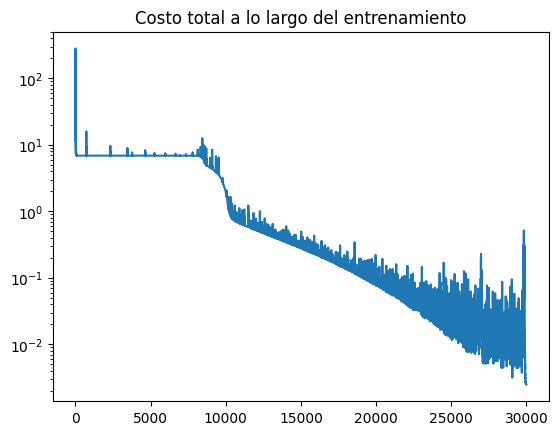

In [ ]:
plt.plot(historial_error)
plt.yscale("log")
plt.title("Costo total a lo largo del entrenamiento")

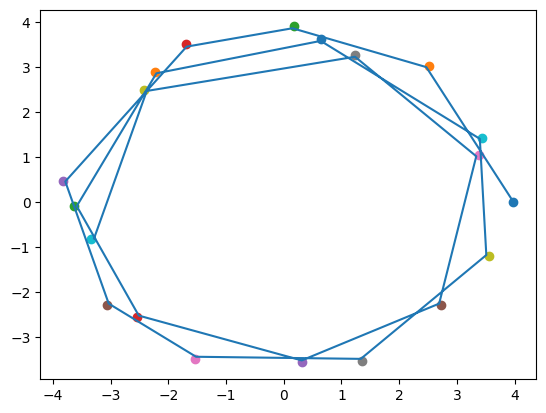

In [ ]:
x = modelo(T_train)[0].cpu().detach()

plt.plot(x[:,0],x[:,1])
for i in range(len(t_data)):
  plt.scatter(x_data[i], y_data[i])

El modelo no sigue muy bien a los datos, pero no nos preocupa porque la parte en la que se enfocaba el entrenamiento era la de las velocidades. Extraemos los parametros del vortice que aprendio el modelo, e implementamos el campo de velocidades.

In [ ]:
alp = modelo.alp[0]
r02 = modelo.r02[0]
Gam = modelo.Gam[0]
print("alpha: "+str(alp.item()))
print("r^2: " + str(r02.item()))
print("gamma: " + str(Gam.item()))

def u(x,t):
  r = torch.linalg.vector_norm(x, ord=2, dim = -1, keepdim=True)
  r_versor = (x/r).view(-1)
  tita_versor = torch.tensor([- r_versor[1], r_versor[0]])

  u_r = - alp * r * r_versor
  u_tita = Gam / (2 * torch.pi * r) * (1- torch.exp(-r**2/r02)) * tita_versor

  return u_r + u_tita

alpha: 0.025045640439432238
r^2: 0.5833813810369461
gamma: 229.95054372941618


E integramos con Runge-Kutta y comparamos con las mediciones

In [ ]:

t_sol = torch.zeros((int(T/dt),1))
x_sol = torch.zeros((int(T/dt),2))

x_sol[0][0] = x_data[0]
x_sol[0][1] = y_data[0]
t_sol[0][0] = T_data[0]

# Uno menos xq ya estan los estados iniciales
for i in range(int(T/dt)-1):
    t_sol[i+1] = t_sol[i] + torch.tensor(dt)
    x_sol[i+1] = esquema4(x_sol[i], u, t_sol[i], dt)

/usr/local/lib/python3.13/dist-packages/torch/utils/_device.py:116: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  return func(*args, **kwargs)


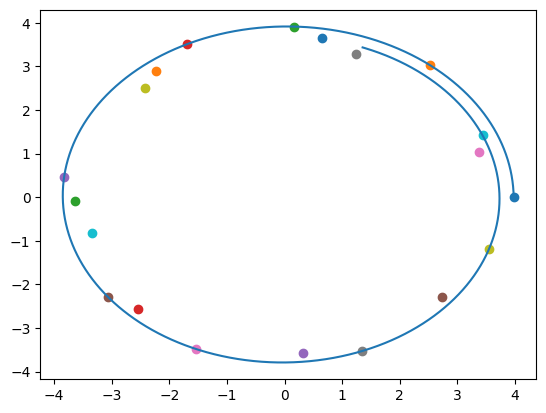

In [ ]:
plt.plot(x_sol[:,0].detach(),x_sol[:,1].detach())
for i in range(len(t_data)):
  plt.scatter(x_data[i], y_data[i])